In [1]:
import numpy as np
import torch
import torch.nn as nn
import scipy.optimize
from scipy.interpolate import griddata
from SALib.sample import sobol_sequence
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from torch.autograd import grad
from kan import *
import time
from datetime import datetime
from utils.logger import Logger
import matplotlib as mpl

#from fast_bspline_kan import KAN
# Plotting
from utils.plotting import colormap_parula
import matplotlib as mpl
from matplotlib import font_manager
# Set Times New Roman fontmpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman']
mpl.rcParams['mathtext.fontset'] = 'stix'    # Use STIX math font, compatible with Times New Roman# Set global font sizestitle_font = 24
axis_label_font = 24
tick_font = 24
cbar_font = 24
legend_font = 24


layers = [2, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 2]
dtype = torch.float64  
device = torch.device("cuda")
torch.manual_seed(324324)
np.random.seed(324324)

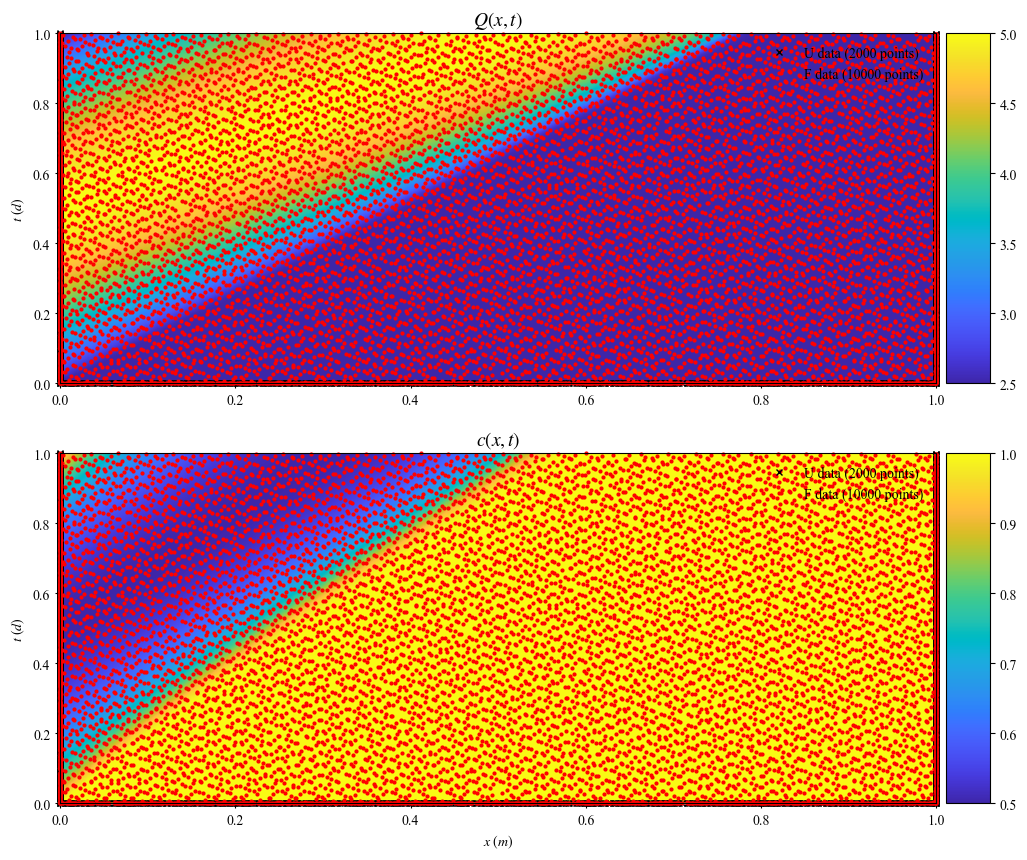

In [2]:
# Numerical solution generation (preserve original logic)Q0 = 2.5
S0 = 0.004
B = 15.0
n = 0.07

N_u = 2000
N_f = 8000

alpha = (n * B ** (2 / 3) / np.sqrt(S0)) ** (3 / 5)

# Spatiotemporal grid (using float64 precision)L = 1.0
dx = 0.00125
Tf = 1.0
dt = 0.001
x = np.arange(0, L + dx, dx, dtype=np.float64)    # Specify numpy array precisiont = np.arange(0, Tf + dt, dt, dtype=np.float64)
X, T = np.meshgrid(x, t)

Q = np.ones_like(X) * Q0
for i, ts in enumerate(T[:, 0]):
    Q[i, 0] += Q0 * np.sin(np.pi * ts)

# Finite difference solverfor l in range(len(t) - 1):
    for i in range(1, len(x)):
        Q[l + 1, i] = Q[l, i] + dt * (Q[l, i] ** (2 / 5) / (alpha * (3 / 5) * dx) * (Q[l, i - 1] - Q[l, i]))

Ac = alpha * Q ** (3 / 5)
V = Ac * dx
c0 = 1
c = np.ones_like(Q) * c0

for l in range(len(t) - 1):
    c[l, 0] = Q0 * c0 / Q[l, 0]
    for i in range(1, len(x)):
        c[l + 1, i] = (V[l, i] * c[l, i] + (Q[l, i - 1] * c[l, i - 1] - Q[l, i] * c[l, i]) * dt) / \
                        (V[l, i] + (Q[l, i - 1] - Q[l, i]) * dt)


X_star = np.hstack((X.flatten()[:, None], T.flatten()[:, None]))
lb = np.min(X_star, axis=0)
ub = np.max(X_star, axis=0)
lb = lb.astype(np.float64)
ub = ub.astype(np.float64)

# === Training data preparation ===# Boundary and initial conditions (converted to float64)ic = np.hstack((X[0:1, :].T, T[0:1, :].T)).astype(np.float64)
Qic = Q[0:1, :].T.astype(np.float64)
Cic = c[0:1, :].T.astype(np.float64)

# Boundary data (lower and upper boundaries)bcl = np.hstack((X[:, 0:1], T[:, 0:1])).astype(np.float64)
Qlb = Q[:, 0:1].astype(np.float64)
Clb = c[:, 0:1].astype(np.float64)
bcu = np.hstack((X[:, -1:], T[:, -1:])).astype(np.float64)
Qub = Q[:, -1:].astype(np.float64)
Cub = c[:, -1:].astype(np.float64)

# Merge training dataX_u_train = np.vstack([ic, bcl, bcu]).astype(np.float64)
Q_u_train = np.vstack([Qic, Qlb, Qub]).astype(np.float64)
C_u_train = np.vstack([Cic, Clb, Cub]).astype(np.float64)

# Randomly sample training pointsidx = np.random.choice(X_u_train.shape[0], N_u, replace=False)
X_u_train = X_u_train[idx, :].astype(np.float64)
Q_u_train = Q_u_train[idx, :].astype(np.float64)
C_u_train = C_u_train[idx, :].astype(np.float64)

# Generate collocation pointsX_f_train = lb + (ub - lb) * sobol_sequence.sample(N_f, 2)
X_f_train = X_f_train.astype(np.float64)


X_u_train = X_u_train.astype(np.float64)
Q_u_train = Q_u_train.astype(np.float64)
C_u_train = C_u_train.astype(np.float64)

u_train = np.hstack([Q_u_train, C_u_train])

X_f_train = np.vstack((X_f_train, X_u_train))

# Plotting
fig = plt.figure(figsize=(12, 10))
# cmap=colormap_parula,
ax = fig.add_subplot(211)
h = ax.imshow(Q, interpolation='nearest', cmap=colormap_parula,
                extent=[x.min(), x.max(), t.min(), t.max()],
                origin='lower', aspect='auto')
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
fig.colorbar(h, cax=cax)
ax.plot(X_u_train[:, 0], X_u_train[:, 1], 'kx', label='U data (%d points)' % (X_u_train.shape[0]),
        markersize=4, clip_on=False)
ax.plot(X_f_train[:, 0], X_f_train[:, 1], 'r.', label='F data (%d points)' % (X_f_train.shape[0]),
        markersize=4, clip_on=False)
ax.legend(frameon=False, loc='best')
ax.set_title('$Q(x, t)$', fontsize=14)
ax.set_ylabel('$t\ (d)$')
# cmap=colormap_parula,
ax = fig.add_subplot(212)
h = ax.imshow(c, interpolation='nearest', cmap=colormap_parula,
                extent=[x.min(), x.max(), t.min(), t.max()],
                origin='lower', aspect='auto')
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
fig.colorbar(h, cax=cax)
ax.plot(X_u_train[:, 0], X_u_train[:, 1], 'kx', label='U data (%d points)' % (X_u_train.shape[0]),
        markersize=4, clip_on=False)
ax.plot(X_f_train[:, 0], X_f_train[:, 1], 'r.', label='F data (%d points)' % (X_f_train.shape[0]),
        markersize=4, clip_on=False)
ax.legend(frameon=False, loc='best')
ax.set_title('$c(x, t)$', fontsize=14)
ax.set_ylabel('$t\ (d)$')
ax.set_xlabel('$x\ (m)$')

plt.show()

In [3]:
# %% Part 3: Define coupled PINN modelclass SVE_ADE_PINN_MLP(nn.Module):
    def __init__(self, X_u_train, u_train, X_f_train,layers, lb, ub, alpha,Q, c):
        super().__init__()
        
# Boundary condition data        self.x_u = torch.tensor(X_u_train[:,0], dtype=dtype, device=device).unsqueeze(1)
        self.t_u = torch.tensor(X_u_train[:,1], dtype=dtype, device=device).unsqueeze(1)
        self.u_train = torch.tensor(u_train, dtype=dtype, device=device)
        
# Collocation point data        self.x_f = torch.tensor(X_f_train[:,0], dtype=dtype, device=device).unsqueeze(1).requires_grad_(True)
        self.t_f = torch.tensor(X_f_train[:,1], dtype=dtype, device=device).unsqueeze(1).requires_grad_(True)
        
# Normalization parameters        self.lb = torch.tensor(lb, dtype=dtype, device=device)
        self.ub = torch.tensor(ub, dtype=dtype, device=device)
        self.alpha = nn.Parameter(torch.tensor(alpha, dtype=dtype, device=device))

        self.iter = 0
        self.losses = []
        self.err_Q_u = []
        self.err_C_u = []
        self.err_Q_f = []
        self.err_C_f = []
        self.L2_errors_Q = []
        self.L2_errors_C = []
        self.start_time = time.time()
        self.prev_time = self.start_time
        self.log_frequency=100


# Data for L2 error computation        self.X_star = torch.tensor(X_star, dtype=dtype).to(device)
        self.Exact_Q = torch.tensor(Q.flatten()[:, None], dtype=dtype).to(device)
        self.Exact_C = torch.tensor(c.flatten()[:, None], dtype=dtype).to(device)


# MLP network architecture        self.layers = layers
        self.net = self.build_network()
# Initialize parameters        self.net.apply(self.weight_init)
    
    def build_network(self):
        net_layers = []
        input_dim = self.layers[0]
        for i in range(1, len(self.layers)-1):
            output_dim = self.layers[i]
            net_layers.append(nn.Linear(input_dim, output_dim))
            net_layers.append(nn.Tanh())
            input_dim = output_dim
        net_layers.append(nn.Linear(input_dim, self.layers[-1]))
        return nn.Sequential(*net_layers).to(device)
    
    def weight_init(self, m):
        if isinstance(m, nn.Linear):
            nn.init.xavier_normal_(m.weight)
            nn.init.constant_(m.bias, 0.0)
            
    def forward(self, x, t):
        X = torch.cat([x, t], dim=1)
        X = 2.0*(X - self.lb)/(self.ub - self.lb) - 1.0
        output = self.net(X)

        Q = output[:,0:1]
        C = output[:,1:2]
        return Q, C
    
    def net_f(self, x, t):
        x.requires_grad_(True)
        t.requires_grad_(True)
        Q, C = self.forward(x, t)

# Use safer clamp range to prevent gradient explosion        Q_safe = torch.clamp(Q, min=0.1*Q0, max=5*Q0)    # Expand safe range        C_safe = torch.clamp(C, min=0.01*c0, max=4*c0)       # Allow concentration to reach zero        
# SVE equation residual        Q_t = grad(Q_safe, t, grad_outputs=torch.ones_like(Q_safe), create_graph=True)[0]
        Q_x = grad(Q_safe, x, grad_outputs=torch.ones_like(Q_safe), create_graph=True)[0]

        #loss_Q_f = Q_t + (Q_safe**(2/5)/(self.alpha*(3/5))) * Q_x
        
        
        loss_Q_f = Q_t + (Q_safe.pow(2.0/5.0) / (self.alpha * (3.0/5.0))) * Q_x

# ADE equation residual        A = self.alpha * Q_safe.pow(3.0/5.0)
        C_t = grad(C_safe, t, grad_outputs=torch.ones_like(C_safe), create_graph=True)[0]
        QC_x = grad(Q_safe * C_safe, x, grad_outputs=torch.ones_like(Q_safe), create_graph=True)[0]
        A_t = grad(A, t, grad_outputs=torch.ones_like(A), create_graph=True)[0]  # ∂A/∂t
        
        loss_C_f = A * C_t + C_safe * A_t + QC_x
        
        return loss_Q_f, loss_C_f
    

    def L2_error(self):
# Full-domain L2 error (no gradient tracking)        with torch.no_grad():
            Q_pred, C_pred = self.forward(self.X_star[:, 0:1], self.X_star[:, 1:2])
            L2_error_Q = (torch.linalg.norm(Q_pred - self.Exact_Q) / 
                         torch.linalg.norm(self.Exact_Q))
            L2_error_C = (torch.linalg.norm(C_pred - self.Exact_C) / 
                         torch.linalg.norm(self.Exact_C))
        return L2_error_Q, L2_error_C
    

    def loss_fn(self):
        
# Boundary condition loss        Q_pred, C_pred = self.forward(self.x_u, self.t_u)

        loss_Q_u = torch.mean((self.u_train[:,0:1] - Q_pred)**2)
        loss_C_u = torch.mean((self.u_train[:,1:2] - C_pred)**2)
        
# PDE residual loss        loss_Q_f, loss_C_f = self.net_f(self.x_f, self.t_f)

        loss_Q_f = torch.mean(loss_Q_f**2) 
        loss_C_f = torch.mean(loss_C_f**2)
        
        total_loss = (loss_Q_u + loss_Q_f) + (loss_C_u + loss_C_f)
        
        return (total_loss, loss_Q_u, loss_Q_f, loss_C_u,  loss_C_f)
    
    def train_model(self, Adam_iters, LBFGS_iters=None):
# Adam optimization phase        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        print("--- Starting Adam Optimization ---")
        for epoch in range(Adam_iters):
            self.iter += 1
            optimizer.zero_grad()
            total_loss, loss_Q_u, loss_Q_f, loss_C_u, loss_C_f = self.loss_fn()
            L2_error_Q, L2_error_C = self.L2_error()
            total_loss.backward()
            optimizer.step()
            
# Record losses            self.losses.append(total_loss.item())
            self.err_Q_u.append(loss_Q_u.item())
            self.err_C_u.append(loss_C_u.item())
            self.err_Q_f.append(loss_Q_f.item())
            self.err_C_f.append(loss_C_f.item())
            self.L2_errors_Q.append(L2_error_Q.item())
            self.L2_errors_C.append(L2_error_C.item())
            
            if epoch % self.log_frequency == 0:
                elapsed = self.get_elapsed()
                epoch_duration = self.get_epoch_duration()
                print(f'Epoch {epoch:6d}: Loss={total_loss.item():.8e}, '
                      f'Q_u={loss_Q_u.item():.8e}, Q_f={loss_Q_f.item():.8e}, '
                      f'C_u={loss_C_u.item():.8e}, C_f={loss_C_f.item():.8e}, '
                      f'L2_Q: {L2_error_Q.item():.8e}, L2_C: {L2_error_C.item():.8e}, '
                      f'Elapsed: {elapsed}(+{epoch_duration})')

# L-BFGS optimization phase        if LBFGS_iters is not None:
            print("--- Starting L-BFGS Optimization ---")
            optimizer = torch.optim.LBFGS(self.parameters(), max_iter=LBFGS_iters, max_eval=LBFGS_iters, 
                                         history_size=100, tolerance_grad=1e-20, tolerance_change=1e-20, 
                                         line_search_fn='strong_wolfe')
        
            def closure():
                optimizer.zero_grad()
                total_loss, loss_Q_u, loss_Q_f, loss_C_u, loss_C_f = self.loss_fn()
                L2_error_Q, L2_error_C = self.L2_error()
                total_loss.backward()
                
# Record losses                self.losses.append(total_loss.item())
                self.err_Q_u.append(loss_Q_u.item())
                self.err_C_u.append(loss_C_u.item())
                self.err_Q_f.append(loss_Q_f.item())
                self.err_C_f.append(loss_C_f.item())
                self.L2_errors_Q.append(L2_error_Q.item())
                self.L2_errors_C.append(L2_error_C.item())
                
                if self.iter % 20 == 0:
                    elapsed = self.get_elapsed()
                    epoch_duration = self.get_epoch_duration()
                    print(f'L-BFGS Step {self.iter}: Loss={total_loss.item():.8e}, '
                          f'Q_u={loss_Q_u.item():.8e}, Q_f={loss_Q_f.item():.8e}, '
                          f'C_u={loss_C_u.item():.8e}, C_f={loss_C_f.item():.8e}, '
                          f'L2_Q: {L2_error_Q.item():.8e}, L2_C: {L2_error_C.item():.8e}, '
                          f'Elapsed: {elapsed}(+{epoch_duration})')
                
                self.iter += 1
                return total_loss
            
            optimizer.step(closure)

# Plot loss curves        plt.figure(figsize=(12, 8))
        plt.subplot(2, 1, 1)
        plt.plot(self.losses, label="Total Loss")
        plt.plot(self.err_Q_u, label="Q_u Loss")
        plt.plot(self.err_Q_f, label="Q_f Loss")
        plt.plot(self.err_C_u, label="C_u Loss")
        plt.plot(self.err_C_f, label="C_f Loss")
        plt.yscale("log")
        plt.legend()
        plt.xlabel("Iterations")
        plt.ylabel("Loss")
        plt.title("Training Losses")
        
# Plot L2 error curves        plt.subplot(2, 1, 2)
        plt.plot(self.L2_errors_Q, label="L2 Error (Q)")
        plt.plot(self.L2_errors_C, label="L2 Error (C)")
        plt.yscale("log")
        plt.legend()
        plt.xlabel("Iterations")
        plt.ylabel("L2 Error")
        plt.title("L2 Errors during Training")
        plt.tight_layout()
        
        return self.losses, self.err_Q_u, self.err_C_u, self.err_Q_f, self.err_C_f, self.L2_errors_Q, self.L2_errors_C

    def predict(self, X_star):
        self.eval()
        if isinstance(X_star, np.ndarray):
            x = torch.as_tensor(X_star[:,0:1], dtype=dtype, device=device)
            t = torch.as_tensor(X_star[:,1:2], dtype=dtype, device=device)
        else:
            x = X_star[:,0:1].clone().detach().to(device)
            t = X_star[:,1:2].clone().detach().to(device)
        
        with torch.no_grad():
            Q_pred, C_pred = self.forward(x, t)
        return Q_pred.cpu().numpy(), C_pred.cpu().numpy()


    def get_epoch_duration(self):
        now = time.time()
        duration = datetime.fromtimestamp(now - self.prev_time).strftime("%S.%f")[:-5]
        self.prev_time = now
        return duration
    
    def get_elapsed(self):
        return datetime.fromtimestamp(time.time() - self.start_time).strftime("%M:%S")
    
    def predict(self, X_star):
        self.eval()
        x = X_star[:,0:1].to(device)
        t = X_star[:,1:2].to(device)
        with torch.no_grad():
            Q_pred, C_pred = self.forward(x, t)
        return Q_pred.cpu().numpy(), C_pred.cpu().numpy()

In [4]:
# %% Part 3: Define coupled PINN modelclass SVE_ADE_PINN_KAN(nn.Module):
    def __init__(self, X_u_train, u_train, X_f_train, lb, ub, alpha,Q, c):
        super().__init__()
        
# Boundary condition data        self.x_u = torch.tensor(X_u_train[:,0], dtype=dtype, device=device).unsqueeze(1)
        self.t_u = torch.tensor(X_u_train[:,1], dtype=dtype, device=device).unsqueeze(1)
        self.u_train = torch.tensor(u_train, dtype=dtype, device=device)
        
# Collocation point data        self.x_f = torch.tensor(X_f_train[:,0], dtype=dtype, device=device).unsqueeze(1).requires_grad_(True)
        self.t_f = torch.tensor(X_f_train[:,1], dtype=dtype, device=device).unsqueeze(1).requires_grad_(True)
        
# Normalization parameters        self.lb = torch.tensor(lb, dtype=dtype, device=device)
        self.ub = torch.tensor(ub, dtype=dtype, device=device)
        self.alpha = nn.Parameter(torch.tensor(alpha, dtype=dtype, device=device))

        self.iter = 0
        self.losses = []
        self.err_Q_u = []
        self.err_C_u = []
        self.err_Q_f = []
        self.err_C_f = []
        self.L2_errors_Q = []
        self.L2_errors_C = []
        self.start_time = time.time()
        self.prev_time = self.start_time
        self.log_frequency=100

# Data for L2 error computation        self.X_star = torch.tensor(X_star, dtype=dtype).to(device)
        self.Exact_Q = torch.tensor(Q.flatten()[:, None], dtype=dtype).to(device)
        self.Exact_C = torch.tensor(c.flatten()[:, None], dtype=dtype).to(device)


# KAN network architecture        self.KAN =KAN(width=[2, 10, 10, 10, 2], grid=25, k=5, base_fun=torch.nn.Tanh(),  device=device).to(torch.float64)

            
    def forward(self, x, t):
        X = torch.cat([x, t], dim=1)
        X = 2.0*(X - self.lb)/(self.ub - self.lb) - 1.0
        output = self.KAN(X)
        Q = output[:,0:1]
        C = output[:,1:2]
        return Q, C
    
    def net_f(self, x, t):
        x.requires_grad_(True)
        t.requires_grad_(True)
        Q, C = self.forward(x, t)

# Use safer clamp range to prevent gradient explosion        Q_safe = torch.clamp(Q, min=0.1*Q0, max=5*Q0)    # Expand safe range        C_safe = torch.clamp(C, min=0.01*c0, max=4*c0)       # Allow concentration to reach zero        
# SVE equation residual        Q_t = grad(Q_safe, t, grad_outputs=torch.ones_like(Q_safe), create_graph=True)[0]
        Q_x = grad(Q_safe, x, grad_outputs=torch.ones_like(Q_safe), create_graph=True)[0]

        #loss_Q_f = Q_t + (Q_safe**(2/5)/(self.alpha*(3/5))) * Q_x
        
        
        loss_Q_f = Q_t + (Q_safe.pow(2.0/5.0) / (self.alpha * (3.0/5.0))) * Q_x

# ADE equation residual        A = self.alpha * Q_safe.pow(3.0/5.0)
        C_t = grad(C_safe, t, grad_outputs=torch.ones_like(C_safe), create_graph=True)[0]
        QC_x = grad(Q_safe * C_safe, x, grad_outputs=torch.ones_like(Q_safe), create_graph=True)[0]
        A_t = grad(A, t, grad_outputs=torch.ones_like(A), create_graph=True)[0]  # ∂A/∂t
        
        loss_C_f = A * C_t + C_safe * A_t + QC_x
        
        return loss_Q_f, loss_C_f
    

    def L2_error(self):
# Full-domain L2 error (no gradient tracking)        with torch.no_grad():
            Q_pred, C_pred = self.forward(self.X_star[:, 0:1], self.X_star[:, 1:2])
            L2_error_Q = (torch.linalg.norm(Q_pred - self.Exact_Q) / 
                         torch.linalg.norm(self.Exact_Q))
            L2_error_C = (torch.linalg.norm(C_pred - self.Exact_C) / 
                         torch.linalg.norm(self.Exact_C))
        return L2_error_Q, L2_error_C
    

    def loss_fn(self):
        
# Boundary condition loss        Q_pred, C_pred = self.forward(self.x_u, self.t_u)

        loss_Q_u = torch.mean((self.u_train[:,0:1] - Q_pred)**2)
        loss_C_u = torch.mean((self.u_train[:,1:2] - C_pred)**2)
        
# PDE residual loss        loss_Q_f, loss_C_f = self.net_f(self.x_f, self.t_f)

        loss_Q_f = torch.mean(loss_Q_f**2) 
        loss_C_f = torch.mean(loss_C_f**2)
        
        total_loss = (loss_Q_u + loss_Q_f) + (loss_C_u + loss_C_f)
        
        return (total_loss, loss_Q_u, loss_Q_f, loss_C_u,  loss_C_f)
    
    def train_model(self, Adam_iters, LBFGS_iters=None):
# Adam optimization phase        optimizer = torch.optim.Adam(self.parameters(), lr=1e-3)
        print("--- Starting Adam Optimization ---")
        for epoch in range(Adam_iters):
            self.iter += 1
            optimizer.zero_grad()
            total_loss, loss_Q_u, loss_Q_f, loss_C_u, loss_C_f = self.loss_fn()
            L2_error_Q, L2_error_C = self.L2_error()
            total_loss.backward()
            optimizer.step()
            
# Record losses            self.losses.append(total_loss.item())
            self.err_Q_u.append(loss_Q_u.item())
            self.err_C_u.append(loss_C_u.item())
            self.err_Q_f.append(loss_Q_f.item())
            self.err_C_f.append(loss_C_f.item())
            self.L2_errors_Q.append(L2_error_Q.item())
            self.L2_errors_C.append(L2_error_C.item())
            
            if epoch % self.log_frequency == 0:
                elapsed = self.get_elapsed()
                epoch_duration = self.get_epoch_duration()
                print(f'Epoch {epoch:6d}: Loss={total_loss.item():.8e}, '
                      f'Q_u={loss_Q_u.item():.8e}, Q_f={loss_Q_f.item():.8e}, '
                      f'C_u={loss_C_u.item():.8e}, C_f={loss_C_f.item():.8e}, '
                      f'L2_Q: {L2_error_Q.item():.8e}, L2_C: {L2_error_C.item():.8e}, '
                      f'Elapsed: {elapsed}(+{epoch_duration})')

# L-BFGS optimization phase        if LBFGS_iters is not None:
            print("--- Starting L-BFGS Optimization ---")
            optimizer = torch.optim.LBFGS(self.parameters(), max_iter=LBFGS_iters, max_eval=LBFGS_iters, 
                                         history_size=100, tolerance_grad=1e-20, tolerance_change=1e-20, 
                                         line_search_fn='strong_wolfe')
        
            def closure():
                optimizer.zero_grad()
                total_loss, loss_Q_u, loss_Q_f, loss_C_u, loss_C_f = self.loss_fn()
                L2_error_Q, L2_error_C = self.L2_error()
                total_loss.backward()
                
# Record losses                self.losses.append(total_loss.item())
                self.err_Q_u.append(loss_Q_u.item())
                self.err_C_u.append(loss_C_u.item())
                self.err_Q_f.append(loss_Q_f.item())
                self.err_C_f.append(loss_C_f.item())
                self.L2_errors_Q.append(L2_error_Q.item())
                self.L2_errors_C.append(L2_error_C.item())
                
                if self.iter % 20 == 0:
                    elapsed = self.get_elapsed()
                    epoch_duration = self.get_epoch_duration()
                    print(f'L-BFGS Step {self.iter}: Loss={total_loss.item():.8e}, '
                          f'Q_u={loss_Q_u.item():.8e}, Q_f={loss_Q_f.item():.8e}, '
                          f'C_u={loss_C_u.item():.8e}, C_f={loss_C_f.item():.8e}, '
                          f'L2_Q: {L2_error_Q.item():.8e}, L2_C: {L2_error_C.item():.8e}, '
                          f'Elapsed: {elapsed}(+{epoch_duration})')
                
                self.iter += 1
                return total_loss
            
            optimizer.step(closure)

# Plot loss curves        plt.figure(figsize=(12, 8))
        plt.subplot(2, 1, 1)
        plt.plot(self.losses, label="Total Loss")
        plt.plot(self.err_Q_u, label="Q_u Loss")
        plt.plot(self.err_Q_f, label="Q_f Loss")
        plt.plot(self.err_C_u, label="C_u Loss")
        plt.plot(self.err_C_f, label="C_f Loss")
        plt.yscale("log")
        plt.legend()
        plt.xlabel("Iterations")
        plt.ylabel("Loss")
        plt.title("Training Losses")
        
# Plot L2 error curves        plt.subplot(2, 1, 2)
        plt.plot(self.L2_errors_Q, label="L2 Error (Q)")
        plt.plot(self.L2_errors_C, label="L2 Error (C)")
        plt.yscale("log")
        plt.legend()
        plt.xlabel("Iterations")
        plt.ylabel("L2 Error")
        plt.title("L2 Errors during Training")
        plt.tight_layout()
        
        return self.losses, self.err_Q_u, self.err_Q_f, self.err_C_u,  self.err_C_f, self.L2_errors_Q, self.L2_errors_C

    def predict(self, X_star):
        self.eval()
        if isinstance(X_star, np.ndarray):
            x = torch.as_tensor(X_star[:,0:1], dtype=dtype, device=device)
            t = torch.as_tensor(X_star[:,1:2], dtype=dtype, device=device)
        else:
            x = X_star[:,0:1].clone().detach().to(device)
            t = X_star[:,1:2].clone().detach().to(device)
        
        with torch.no_grad():
            Q_pred, C_pred = self.forward(x, t)
        return Q_pred.cpu().numpy(), C_pred.cpu().numpy()


    def get_epoch_duration(self):
        now = time.time()
        duration = datetime.fromtimestamp(now - self.prev_time).strftime("%S.%f")[:-5]
        self.prev_time = now
        return duration
    
    def get_elapsed(self):
        return datetime.fromtimestamp(time.time() - self.start_time).strftime("%M:%S")
    
    def predict(self, X_star):
        self.eval()
        x = X_star[:,0:1].to(device)
        t = X_star[:,1:2].to(device)
        with torch.no_grad():
            Q_pred, C_pred = self.forward(x, t)
        return Q_pred.cpu().numpy(), C_pred.cpu().numpy()

In [5]:
mlp_model = SVE_ADE_PINN_MLP(X_u_train, u_train, X_f_train,layers, lb,ub, alpha, Q, c ).double().to(device)
kan_model = SVE_ADE_PINN_KAN(X_u_train, u_train, X_f_train, lb,ub, alpha, Q, c ).double().to(device)

checkpoint directory created: ./model
saving model version 0.0


In [6]:
# Parameter countdef count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nMLP Parameters: {count_parameters(mlp_model):,}")
print(f"KAN Parameters: {count_parameters(kan_model):,}")


MLP Parameters: 23,203
KAN Parameters: 8,641


--- Starting Adam Optimization ---
Epoch      0: Loss=1.06208418e+01, Q_u=9.78110431e+00, Q_f=1.49136319e-02, C_u=8.23260270e-01, C_f=1.56357944e-03, L2_Q: 9.94197724e-01, L2_C: 1.00529414e+00, Elapsed: 00:01(+01.3)
Epoch    100: Loss=1.17533705e-01, Q_u=6.62122366e-02, Q_f=1.65362484e-02, C_u=1.21285774e-02, C_f=2.26566429e-02, L2_Q: 1.05272265e-01, L2_C: 1.23795797e-01, Elapsed: 00:12(+11.1)
Epoch    200: Loss=3.77914057e-02, Q_u=1.18678727e-02, Q_f=1.31069120e-02, C_u=1.12363186e-02, C_f=1.58030239e-03, L2_Q: 5.91386477e-02, L2_C: 1.12957471e-01, Elapsed: 00:23(+11.0)
Epoch    300: Loss=2.80366739e-02, Q_u=6.28095554e-03, Q_f=6.13516259e-03, C_u=1.08738251e-02, C_f=4.74673068e-03, L2_Q: 4.55739559e-02, L2_C: 1.18022147e-01, Elapsed: 00:34(+11.1)
Epoch    400: Loss=1.72135045e-02, Q_u=3.49394783e-03, Q_f=3.55016421e-03, C_u=9.38850724e-03, C_f=7.80885215e-04, L2_Q: 3.56685810e-02, L2_C: 1.09743805e-01, Elapsed: 00:46(+11.4)
Epoch    500: Loss=1.40074045e-02, Q_u=2.48970396e-03, Q_f=2

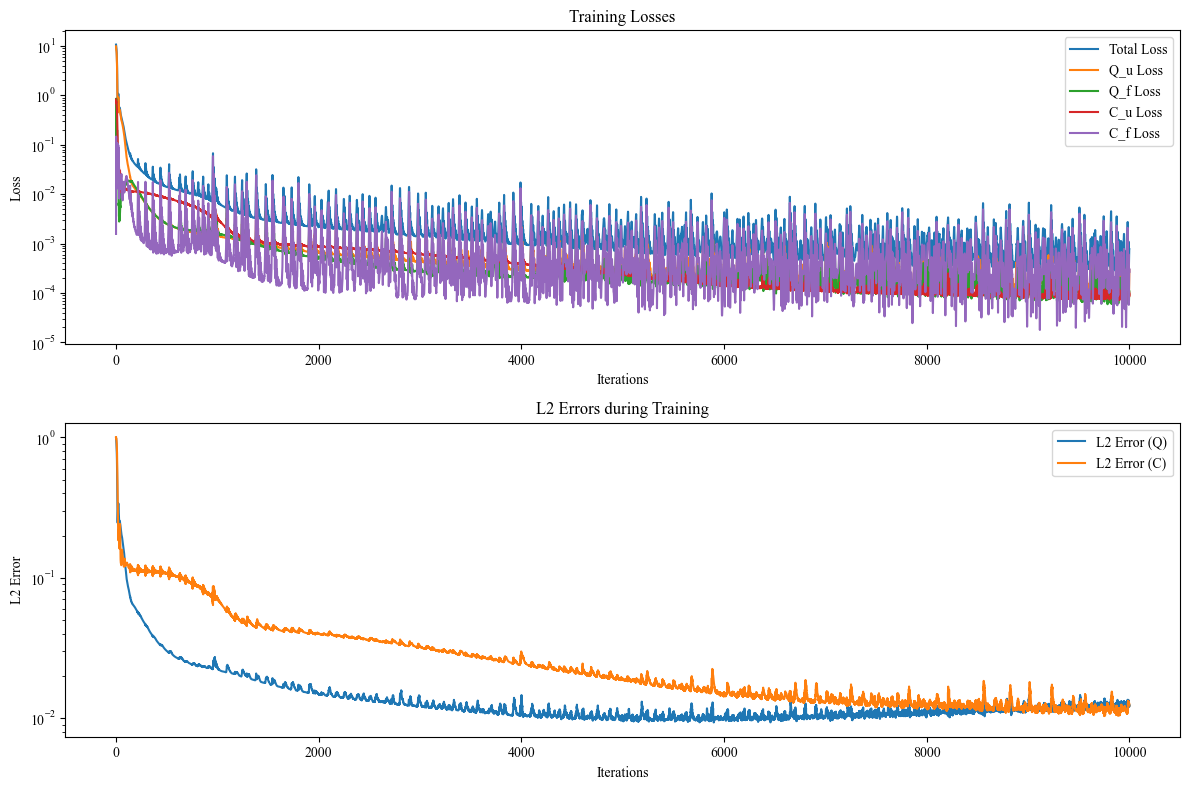

In [7]:
mlp_losses, mlp_err_Q_u, mlp_err_Q_f, mlp_err_C_u, mlp_err_C_f, mlp_L2_errors_Q, mlp_L2_errors_C = mlp_model.train_model(Adam_iters=10001, LBFGS_iters=0)

--- Starting Adam Optimization ---
Epoch      0: Loss=1.09513517e+01, Q_u=1.01654078e+01, Q_f=0.00000000e+00, C_u=7.83444475e-01, C_f=2.49941413e-03, L2_Q: 1.00242012e+00, L2_C: 9.93817721e-01, Elapsed: 18:05(+05.8)
Epoch    100: Loss=1.42103640e+00, Q_u=1.36836641e+00, Q_f=6.34907279e-03, C_u=4.37139194e-02, C_f=2.60699793e-03, L2_Q: 3.98054280e-01, L2_C: 2.07564787e-01, Elapsed: 20:24(+18.6)
Epoch    200: Loss=3.68513477e-01, Q_u=3.50724937e-01, Q_f=9.09692070e-03, C_u=7.72010008e-03, C_f=9.71519926e-04, L2_Q: 2.16933739e-01, L2_C: 1.03838931e-01, Elapsed: 22:44(+20.3)
Epoch    300: Loss=8.87133436e-02, Q_u=7.55980191e-02, Q_f=6.01108864e-03, C_u=6.26302308e-03, C_f=8.41212744e-04, L2_Q: 1.05682920e-01, L2_C: 1.03067442e-01, Elapsed: 25:05(+20.3)
Epoch    400: Loss=2.87420527e-02, Q_u=1.82477366e-02, Q_f=2.81322383e-03, C_u=5.66674858e-03, C_f=2.01434369e-03, L2_Q: 5.15771254e-02, L2_C: 9.93682995e-02, Elapsed: 27:25(+20.6)
Epoch    500: Loss=1.44638013e-02, Q_u=6.61023722e-03, Q_f=1

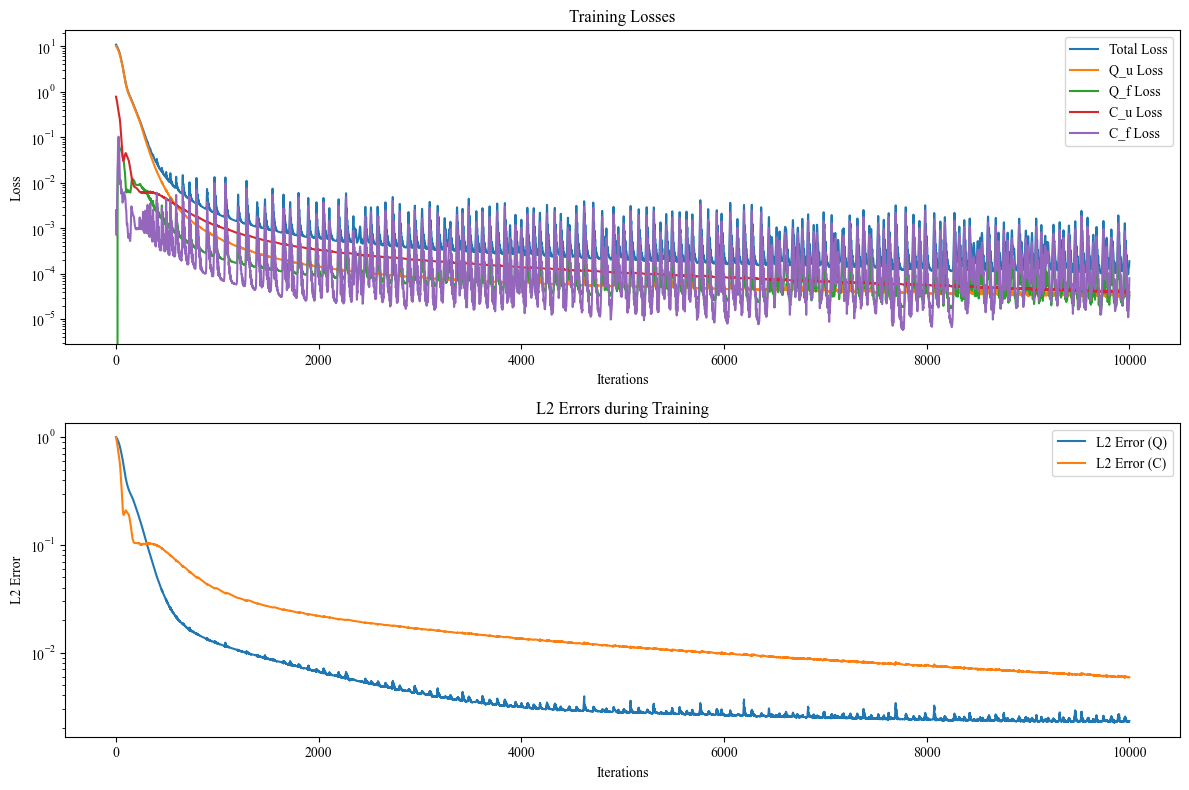

In [8]:
kan_losses, kan_err_Q_u, kan_err_Q_f, kan_err_C_u, kan_err_C_f, kan_L2_errors_Q, kan_L2_errors_C = kan_model.train_model(Adam_iters=10001, LBFGS_iters=0)

In [9]:
X_star_tensor = torch.tensor(X_star, dtype=dtype, device=device)
mlp_Q_pred, mlp_C_pred = mlp_model.predict(X_star_tensor)
mlp_Q_pred = mlp_Q_pred.reshape(X.shape)  
mlp_C_pred = mlp_C_pred.reshape(X.shape)

mlp_error_Q = np.abs(mlp_Q_pred - Q)
mlp_error_C = np.abs(mlp_C_pred - c)

print(f"mlp_Q Relative L2 Error(PIKAN): {np.linalg.norm(mlp_error_Q)/np.linalg.norm(Q):.4e}")
print(f"mlp_C Relative L2 Error(PIKAN): {np.linalg.norm(mlp_error_C)/np.linalg.norm(c):.4e}")

mlp_Q Relative L2 Error(PIKAN): 1.2330e-02
mlp_C Relative L2 Error(PIKAN): 1.2283e-02


In [10]:
X_star_tensor = torch.tensor(X_star, dtype=dtype, device=device)
kan_Q_pred, kan_C_pred = kan_model.predict(X_star_tensor)
kan_Q_pred = kan_Q_pred.reshape(X.shape)  
kan_C_pred = kan_C_pred.reshape(X.shape)

kan_error_Q = np.abs(kan_Q_pred - Q)
kan_error_C = np.abs(kan_C_pred - c)

print(f"kan_Q Relative L2 Error(PIKAN): {np.linalg.norm(kan_error_Q)/np.linalg.norm(Q):.4e}")
print(f"kan_C Relative L2 Error(PIKAN): {np.linalg.norm(kan_error_C)/np.linalg.norm(c):.4e}")

kan_Q Relative L2 Error(PIKAN): 2.3195e-03
kan_C Relative L2 Error(PIKAN): 5.8992e-03


In [11]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

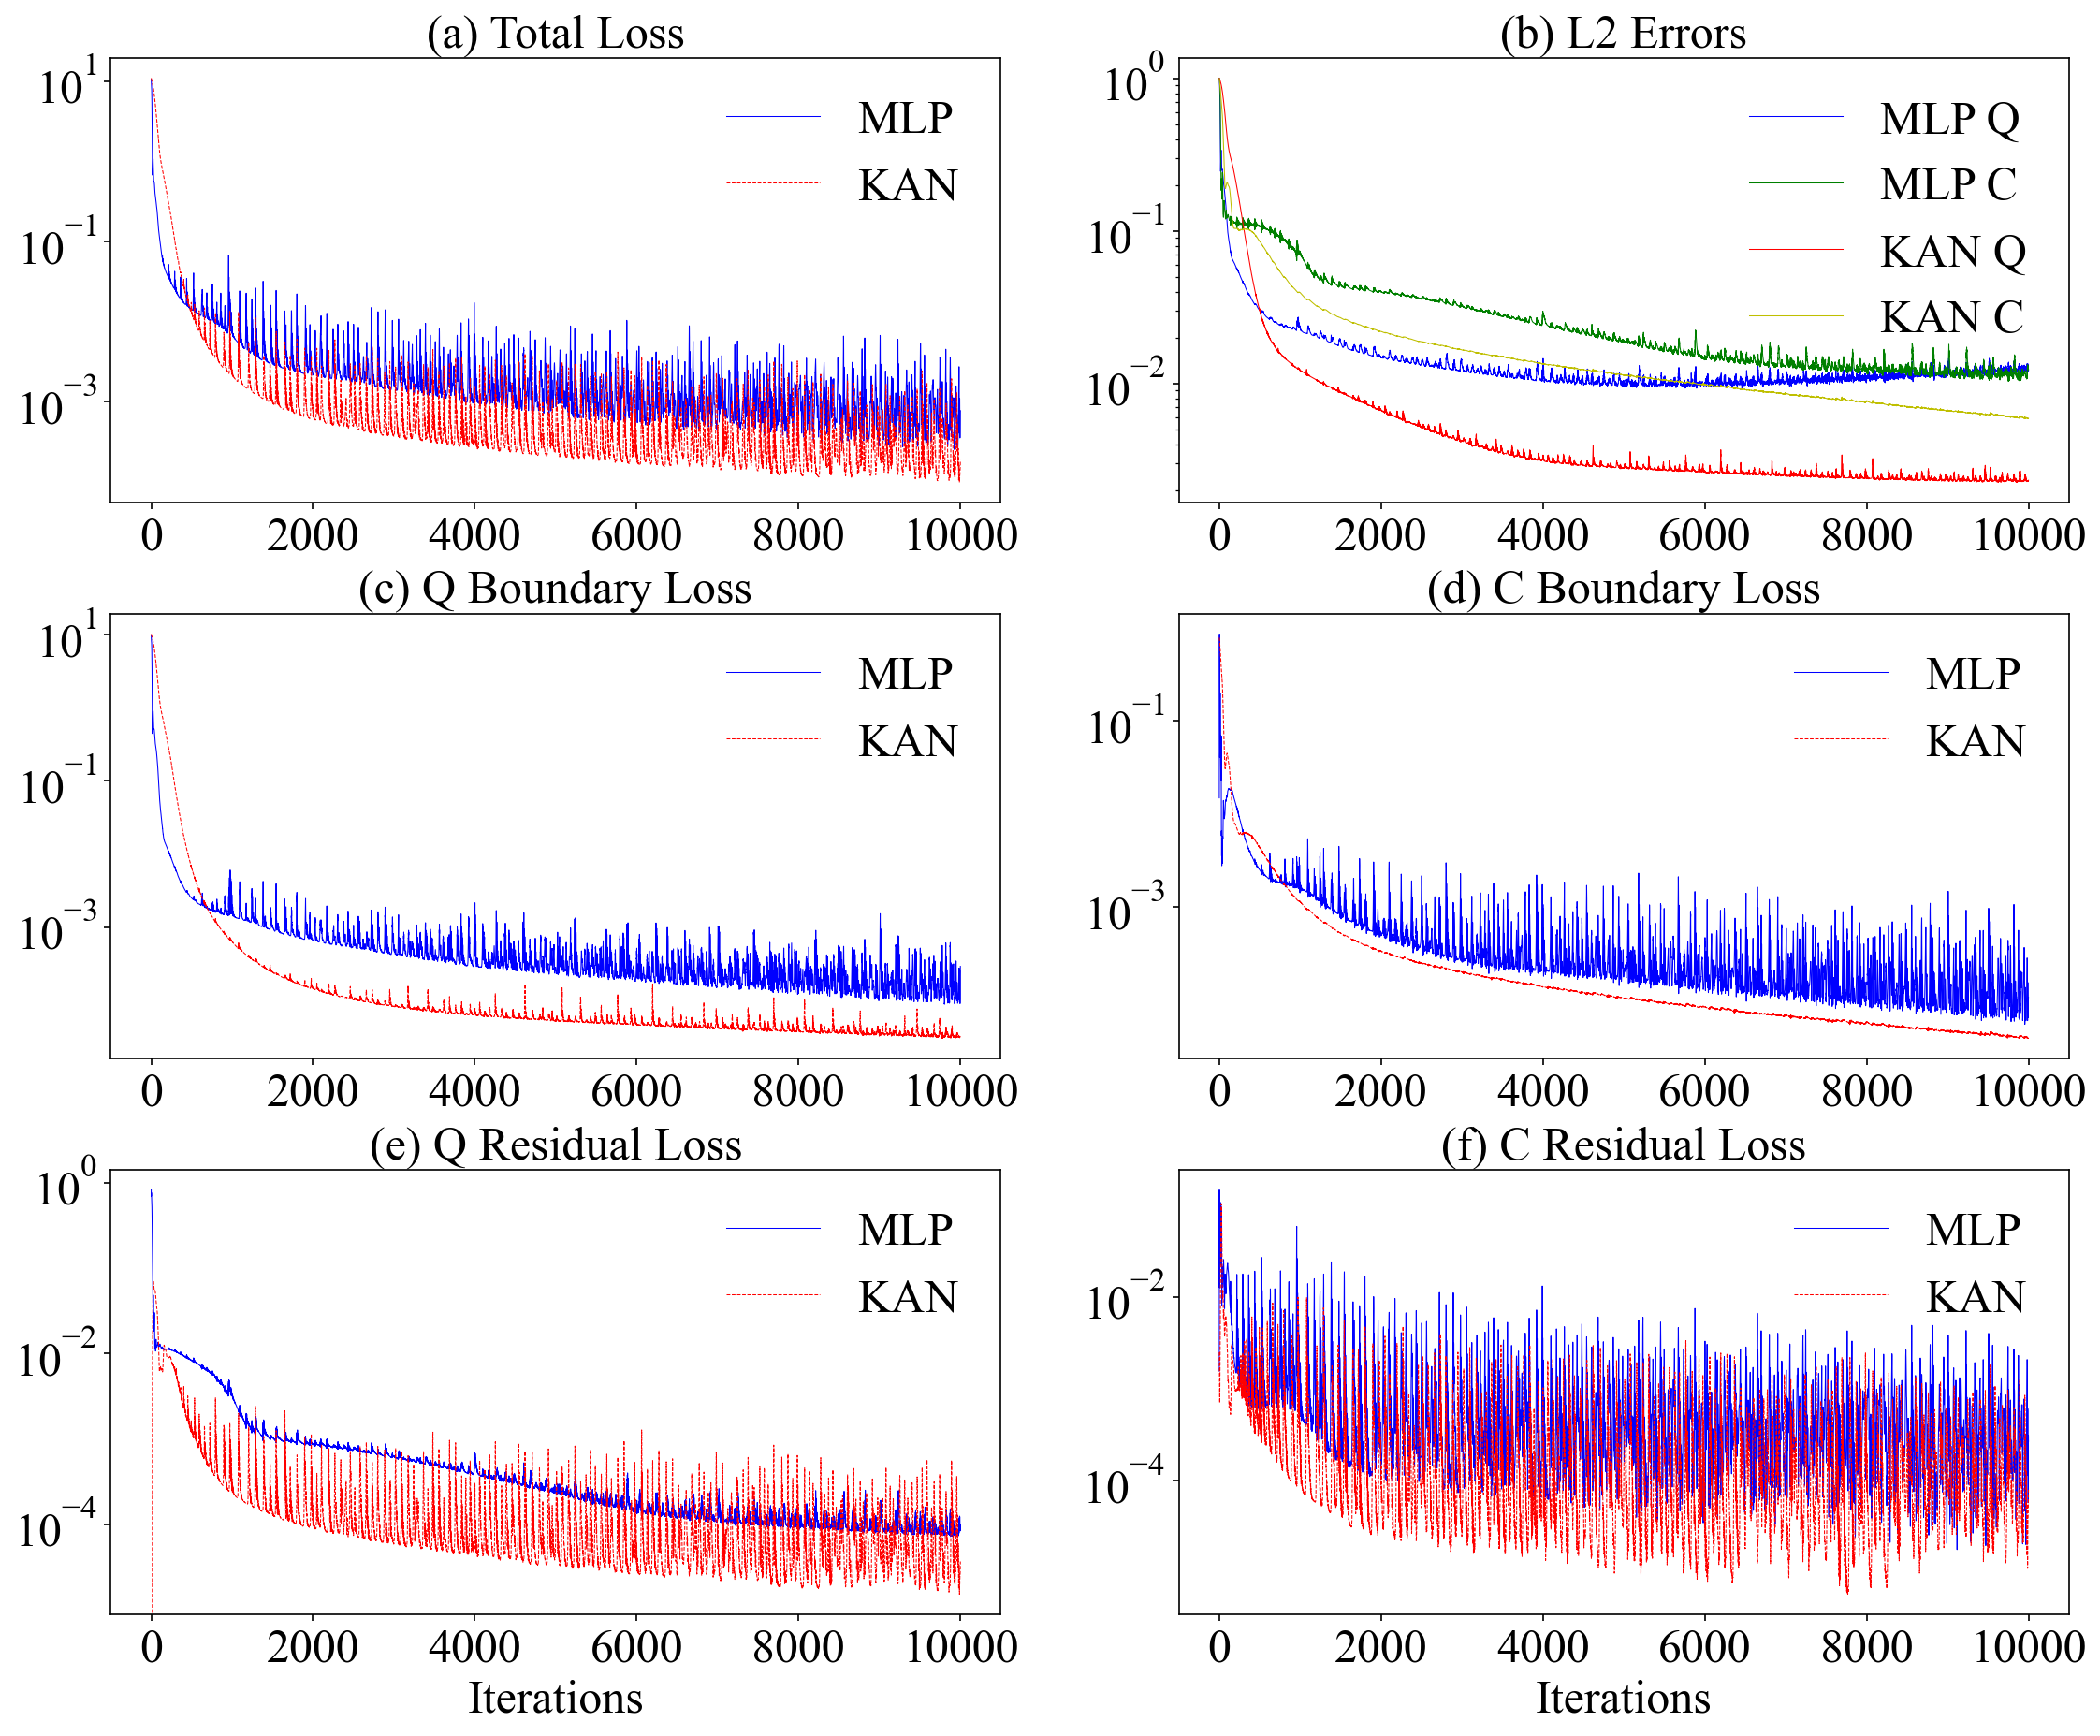

In [18]:
# Create professional layout canvas - 3 rows x 2 columnsfig = plt.figure(figsize=(18, 14.4), dpi=150)
gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1], 
                       hspace=0.25, wspace=0.2)


# Set global font sizestitle_font = 24
axis_label_font = 24
tick_font = 24
cbar_font = 24
legend_font = 24

# (a) Total loss comparisonax0 = fig.add_subplot(gs[0, 0])
ax0.semilogy(mlp_losses, 'b-', linewidth=0.5, label='MLP')
ax0.semilogy(kan_losses, 'r--', linewidth=0.5, label='KAN')
ax0.set_title('(a) Total Loss', fontsize=title_font)
#ax0.set_ylabel('Loss', fontsize=axis_label_font)
ax0.legend(fontsize=legend_font, loc='best', frameon=False)
ax0.tick_params(axis='both', labelsize=tick_font)
# Hide x-axis tick labels#plt.setp(ax0.get_xticklabels(), visible=False)

# (b) L2 error comparisonax5 = fig.add_subplot(gs[0, 1])
ax5.semilogy(mlp_L2_errors_Q, 'b-', linewidth=0.5, label='MLP Q')
ax5.semilogy(mlp_L2_errors_C, 'g-', linewidth=0.5, label='MLP C')
ax5.semilogy(kan_L2_errors_Q, 'r-', linewidth=0.5, label='KAN Q')
ax5.semilogy(kan_L2_errors_C, 'y-', linewidth=0.5, label='KAN C')
ax5.set_title('(b) L2 Errors', fontsize=title_font)
#ax5.set_ylabel('Error', fontsize=axis_label_font)
ax5.legend(fontsize=legend_font, loc='best', frameon=False)
ax5.tick_params(axis='both', labelsize=tick_font)
# Hide x-axis tick labels#plt.setp(ax5.get_xticklabels(), visible=False)

# (c) Q boundary loss comparisonax1 = fig.add_subplot(gs[1, 0])
ax1.semilogy(mlp_err_Q_u, 'b-', linewidth=0.5, label='MLP')
ax1.semilogy(kan_err_Q_u, 'r--', linewidth=0.5, label='KAN')
ax1.set_title('(c) Q Boundary Loss', fontsize=title_font)
#ax1.set_ylabel('Loss', fontsize=axis_label_font)
ax1.legend(fontsize=legend_font, loc='best', frameon=False)
ax1.tick_params(axis='both', labelsize=tick_font)
# Hide x-axis tick labels#plt.setp(ax1.get_xticklabels(), visible=False)

# (d) C boundary loss comparisonax2 = fig.add_subplot(gs[1, 1])
ax2.semilogy(mlp_err_C_u, 'b-', linewidth=0.5, label='MLP')
ax2.semilogy(kan_err_C_u, 'r--', linewidth=0.5, label='KAN')
ax2.set_title('(d) C Boundary Loss', fontsize=title_font)
#ax2.set_ylabel('Loss', fontsize=axis_label_font)
ax2.legend(fontsize=legend_font, loc='best', frameon=False)
ax2.tick_params(axis='both', labelsize=tick_font)
# Hide x-axis tick labels#plt.setp(ax2.get_xticklabels(), visible=False)

# (e) Q residual loss comparisonax3 = fig.add_subplot(gs[2, 0])
ax3.semilogy(mlp_err_Q_f, 'b-', linewidth=0.5, label='MLP')
ax3.semilogy(kan_err_Q_f, 'r--', linewidth=0.5, label='KAN')
ax3.set_title('(e) Q Residual Loss', fontsize=title_font)
ax3.set_xlabel('Iterations', fontsize=axis_label_font)
#ax3.set_ylabel('Loss', fontsize=axis_label_font)
ax3.legend(fontsize=legend_font, loc='best', frameon=False)
ax3.tick_params(axis='both', labelsize=tick_font)

# (f) C residual loss comparisonax4 = fig.add_subplot(gs[2, 1])
ax4.semilogy(mlp_err_C_f, 'b-', linewidth=0.5, label='MLP')
ax4.semilogy(kan_err_C_f, 'r--', linewidth=0.5, label='KAN')
ax4.set_title('(f) C Residual Loss', fontsize=title_font)
ax4.set_xlabel('Iterations', fontsize=axis_label_font)
#ax4.set_ylabel('Loss', fontsize=axis_label_font)
ax4.legend(fontsize=legend_font, loc='best', frameon=False)
ax4.tick_params(axis='both', labelsize=tick_font)

# Save high-quality figureplt.savefig('sve-ade Loss_Comparison.png', 
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')
# Save high-quality figureplt.savefig('sve-ade Loss_Comparison.pdf', 
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')


plt.show()

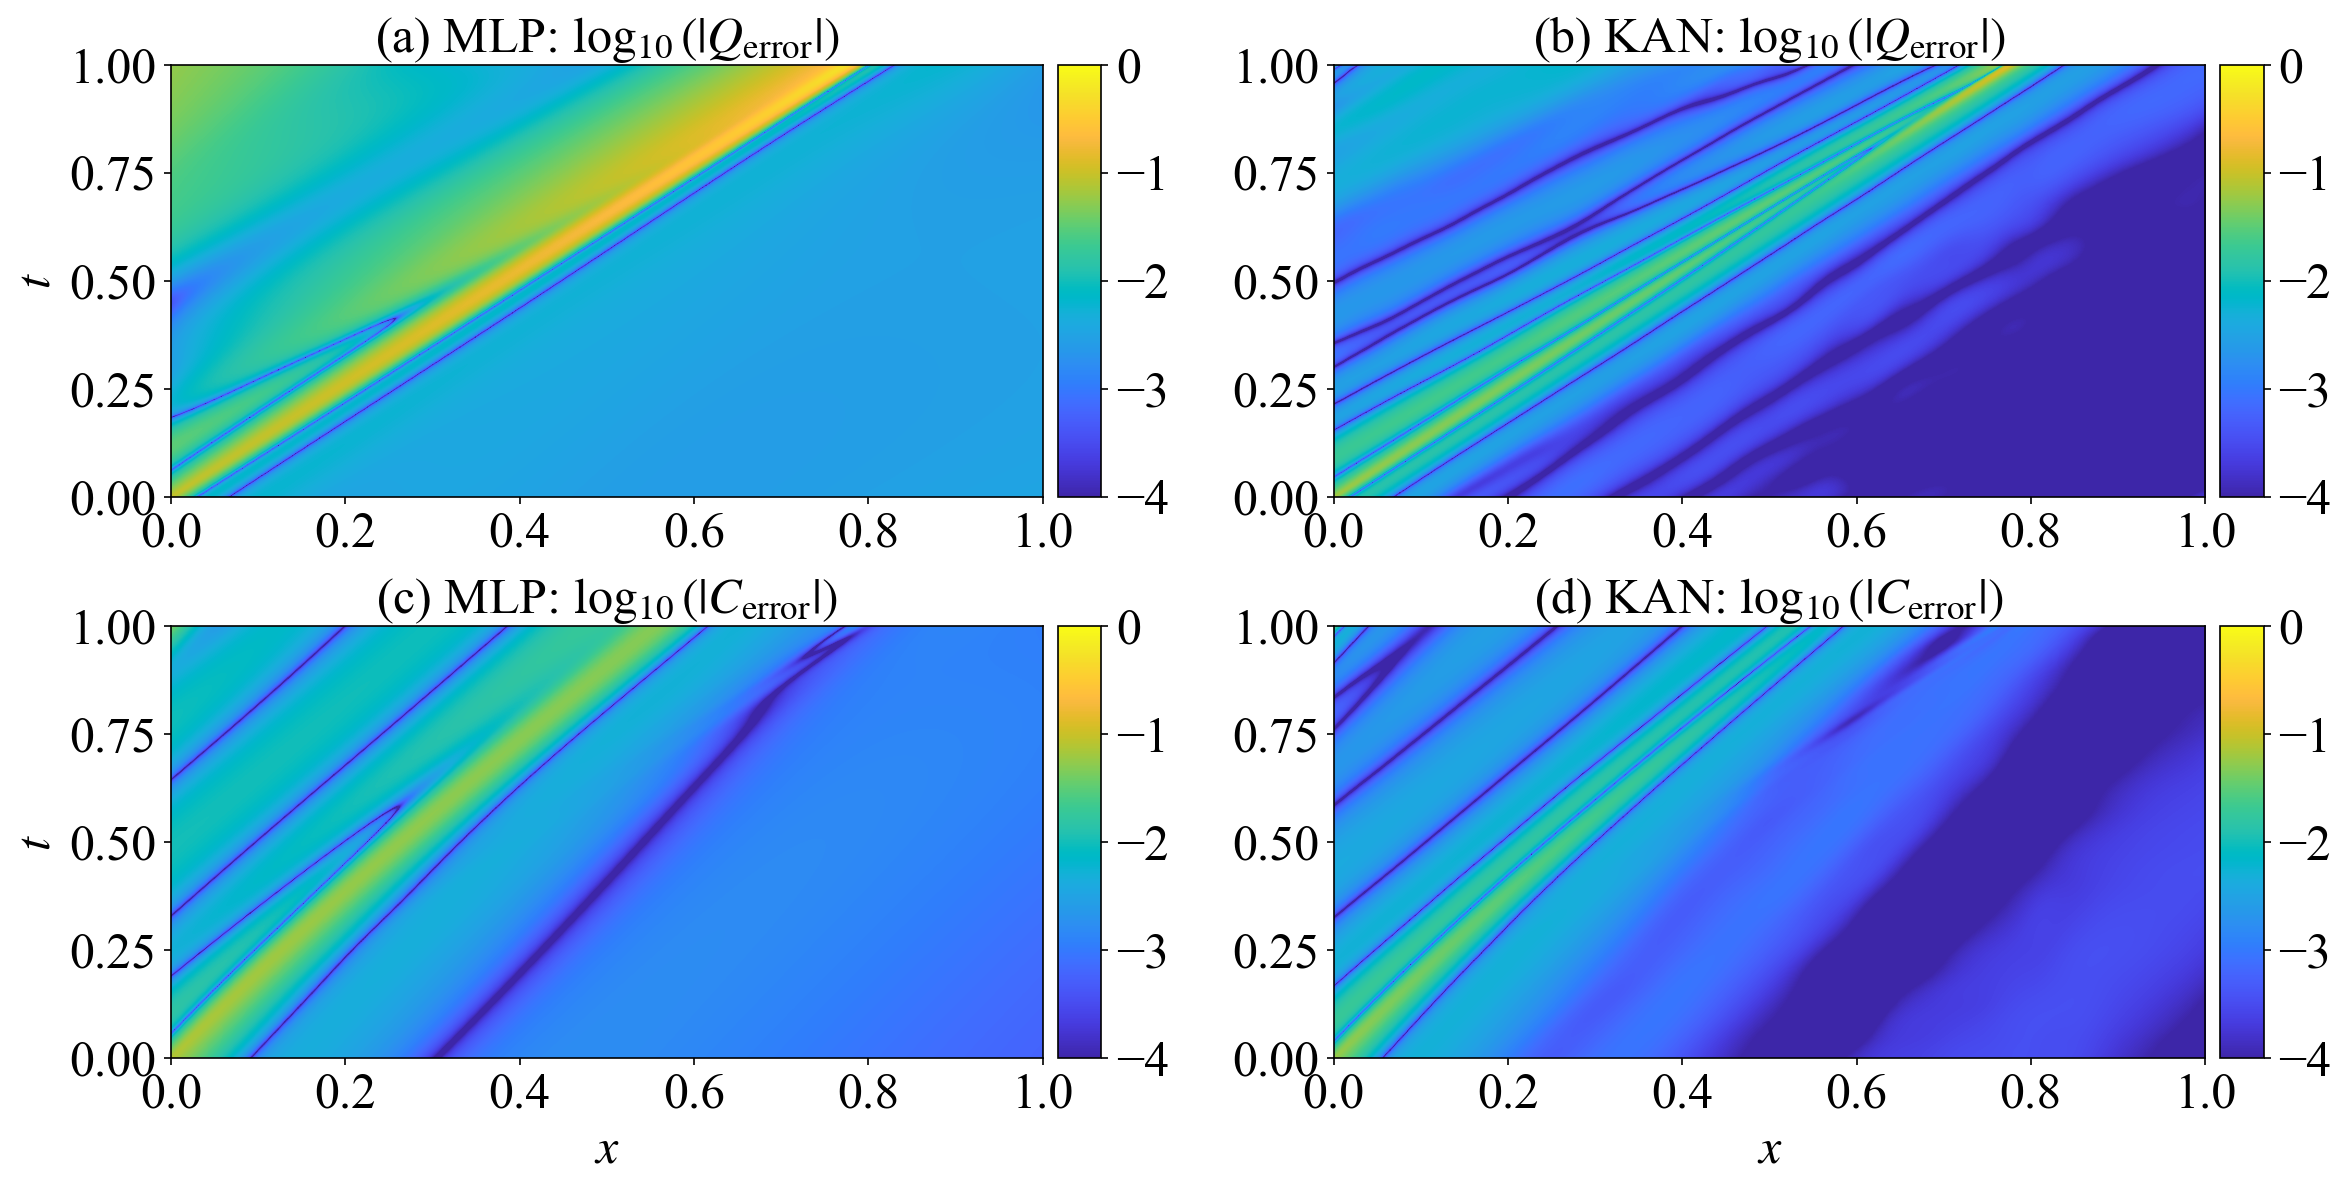

In [19]:
# Compute logarithmic errormlp_log_error_Q = np.log10(np.abs(mlp_error_Q) + 1e-16)
kan_log_error_Q = np.log10(np.abs(kan_error_Q) + 1e-16)
mlp_log_error_C = np.log10(np.abs(mlp_error_C) + 1e-16)
kan_log_error_C = np.log10(np.abs(kan_error_C) + 1e-16)


# Create professional layout canvas - 2 rows x 2 columnsfig = plt.figure(figsize=(18, 8.6), dpi=150)
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1], 
                       hspace=0.3, wspace=0.25)

# Font size parameters - consistent with reference codetitle_font = 24
axis_label_font = 24
tick_font = 24
cbar_font = 24

# (a) MLP Q errorax1 = fig.add_subplot(gs[0, 0])
im1 = ax1.imshow(mlp_log_error_Q, aspect='auto', cmap=colormap_parula,
                 extent=[x.min(), x.max(), t.min(), t.max()],
                 origin='lower', vmin=-4, vmax=0)
ax1.set_title('(a) MLP: $\\log_{10}(|Q_{\\mathrm{error}}|)$', fontsize=title_font)
ax1.set_ylabel('$t$', fontsize=axis_label_font)
ax1.tick_params(axis='both', labelsize=tick_font)
#plt.setp(ax1.get_xticklabels(), visible=False)
divider = make_axes_locatable(ax1)
cax1 = divider.append_axes("right", size="5%", pad=0.1)
cbar1 = fig.colorbar(im1, cax=cax1)
#cbar1.set_label(r'$\log_{10}|\mathrm{Error}|$', rotation=270, labelpad=25, fontsize=cbar_font)
cbar1.ax.tick_params(labelsize=tick_font)

# (b) KAN Q errorax2 = fig.add_subplot(gs[0, 1])
im2 = ax2.imshow(kan_log_error_Q, aspect='auto', cmap=colormap_parula,
                 extent=[x.min(), x.max(), t.min(), t.max()],
                 origin='lower', vmin=-4, vmax=0)
ax2.set_title('(b) KAN: $\\log_{10}(|Q_{\\mathrm{error}}|)$', fontsize=title_font)
ax2.tick_params(axis='both', labelsize=tick_font)
#plt.setp(ax2.get_xticklabels(), visible=False)
divider = make_axes_locatable(ax2)
cax2 = divider.append_axes("right", size="5%", pad=0.1)
cbar2 = fig.colorbar(im2, cax=cax2)
#cbar2.set_label(r'$\log_{10}|\mathrm{Error}|$', rotation=270, labelpad=25, fontsize=cbar_font)
cbar2.ax.tick_params(labelsize=tick_font)

# (c) MLP C errorax3 = fig.add_subplot(gs[1, 0])
im3 = ax3.imshow(mlp_log_error_C, aspect='auto', cmap=colormap_parula,
                 extent=[x.min(), x.max(), t.min(), t.max()],
                 origin='lower', vmin=-4, vmax=0)
ax3.set_title('(c) MLP: $\\log_{10}(|C_{\\mathrm{error}}|)$', fontsize=title_font)
ax3.set_xlabel('$x$', fontsize=axis_label_font)
ax3.set_ylabel('$t$', fontsize=axis_label_font)
ax3.tick_params(axis='both', labelsize=tick_font)
divider = make_axes_locatable(ax3)
cax3 = divider.append_axes("right", size="5%", pad=0.1)
cbar3 = fig.colorbar(im3, cax=cax3)
#cbar3.set_label(r'$\log_{10}|\mathrm{Error}|$', rotation=270, labelpad=25, fontsize=cbar_font)
cbar3.ax.tick_params(labelsize=tick_font)

# (d) KAN C errorax4 = fig.add_subplot(gs[1, 1])
im4 = ax4.imshow(kan_log_error_C, aspect='auto', cmap=colormap_parula,
                 extent=[x.min(), x.max(), t.min(), t.max()],
                 origin='lower', vmin=-4, vmax=0)
ax4.set_title('(d) KAN: $\\log_{10}(|C_{\\mathrm{error}}|)$', fontsize=title_font)
ax4.set_xlabel('$x$', fontsize=axis_label_font)
ax4.tick_params(axis='both', labelsize=tick_font)
divider = make_axes_locatable(ax4)
cax4 = divider.append_axes("right", size="5%", pad=0.1)
cbar4 = fig.colorbar(im4, cax=cax4)
#cbar4.set_label(r'$\log_{10}|\mathrm{Error}|$', rotation=270, labelpad=25, fontsize=cbar_font)
cbar4.ax.tick_params(labelsize=tick_font)

# Save high-quality figureplt.savefig('Log_Error_Maps.png', 
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')
plt.savefig('Log_Error_Maps.pdf', 
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')
plt.show()

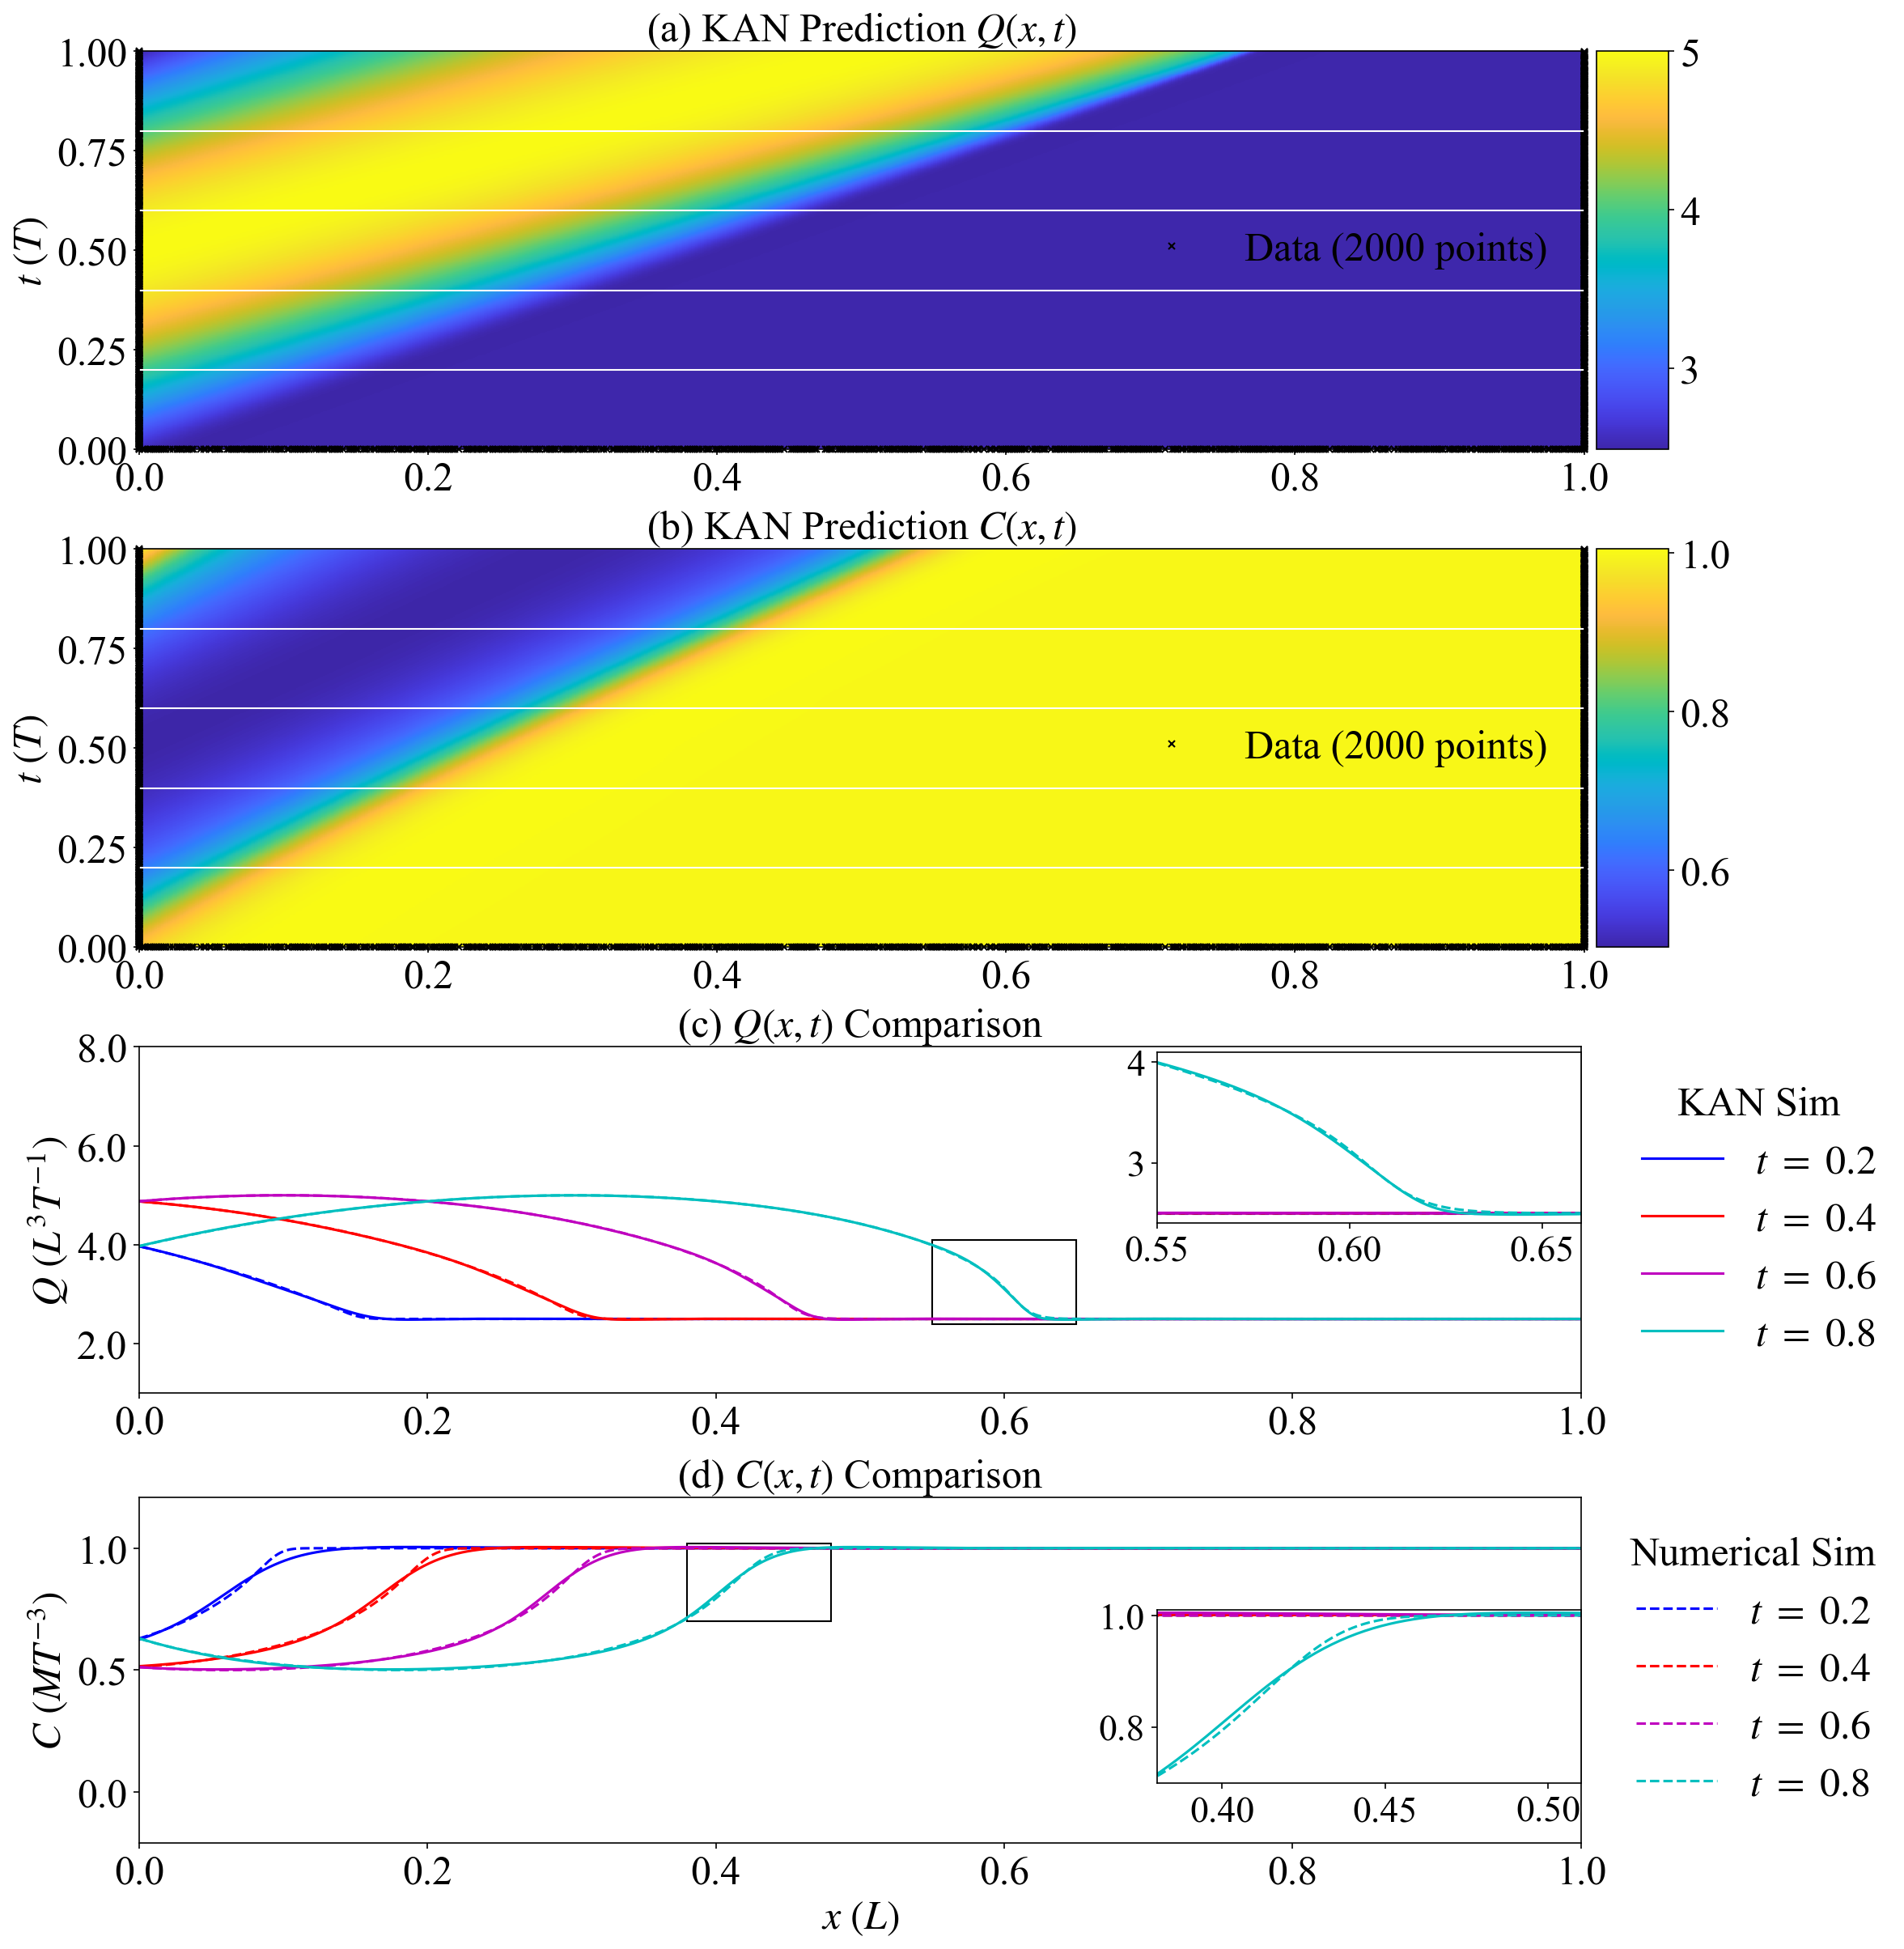

In [20]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.patches import Rectangle    # Import Rectangle for drawing rectangular frames
# Font size parameters - consistent with reference codetitle_font = 24
axis_label_font =24
tick_font = 24
legend_font = 24
cbar_font =24
legend_title_font = 24

# Create professional layout canvas - adjust size to maintain same ratio as previous figuresfig = plt.figure(figsize=(18, 16.4), dpi=150)
ax = fig.add_subplot(111)
ax.axis('off')

# Adjust subplot position and sizegs0 = gridspec.GridSpec(1, 1)
gs0.update(top=1-0.05, bottom=1-1/4, left=0.15, right=0.85, wspace=0)
ax0 = plt.subplot(gs0[0, 0])
h = ax0.imshow(kan_Q_pred, interpolation='nearest', cmap=colormap_parula,
               extent=[x.min(), x.max(), t.min(), t.max()],
               origin='lower', aspect='auto')
divider = make_axes_locatable(ax0)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(h, cax=cax)
cbar.ax.tick_params(labelsize=tick_font)
ax0.plot(X_u_train[:, 0], X_u_train[:, 1], 'kx', label='Data (%d points)' % (Q_u_train.shape[0]),
        markersize=4, clip_on=False)

tpos = np.array([200, 400, 600, 800])
colors = ['b', 'r', 'm', 'c', 'k']

line = np.linspace(x.min(), x.max(), 2)[:, None]
for i in tpos:
    ax0.plot(line, t[i] * np.ones((2, 1)), 'w-', linewidth=1)
ax0.set_ylabel('$t\ (T)$', fontsize=axis_label_font)
ax0.legend(frameon=False, loc='best', fontsize=legend_font)
ax0.set_title('(a) KAN Prediction $Q(x,t)$', fontsize=title_font)
ax0.tick_params(axis='both', labelsize=tick_font)

gs1 = gridspec.GridSpec(1, 1)
gs1.update(top=1 - 1/4 - 0.05, bottom=1 - 1 / 2, left=0.15, right=0.85, wspace=0)
ax1 = plt.subplot(gs1[0, 0])
h = ax1.imshow(kan_C_pred, interpolation='nearest', cmap=colormap_parula,
               extent=[x.min(), x.max(), t.min(), t.max()],
               origin='lower', aspect='auto')
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(h, cax=cax)
cbar.ax.tick_params(labelsize=tick_font)
ax1.plot(X_u_train[:, 0], X_u_train[:, 1], 'kx', label='Data (%d points)' % (C_u_train.shape[0]),
        markersize=4, clip_on=False)

for i in tpos:
    ax1.plot(line, t[i] * np.ones((2, 1)), 'w-', linewidth=1)
ax1.set_ylabel('$t\ (T)$', fontsize=axis_label_font)
ax1.legend(frameon=False, loc='best', fontsize=legend_font)
ax1.set_title('(b) KAN Prediction $C(x,t)$', fontsize=title_font)
ax1.tick_params(axis='both', labelsize=tick_font)

gs2 = gridspec.GridSpec(2, 1)
gs2.update(top=1-1/2-0.05, bottom=0.05, left=0.15, right=0.81, hspace=0.3)

ax2 = plt.subplot(gs2[0, 0])
for i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax2.plot(x, kan_Q_pred[i, :], color, label='$t\ =\ %.1f$' % ts)
    ax2.plot(x, Q[i, :], color + '--')
ax2.set_ylabel('$Q\ (L^3T^{-1})$', fontsize=axis_label_font)
ax2.set_xlim([x.min(), x.max()])
ax2.set_ylim([1, 8])
ax2.set_yticks([2, 4, 6, 8])
ax2.set_yticklabels(['2.0', '4.0', '6.0', '8.0'])
# Modify ax2 legend (MLP Sim)ax2.legend(title="KAN Sim",
           loc="right",
           bbox_to_anchor=(1.23,0.50),
           ncol=1, 
           frameon=False,
           fontsize=legend_font,                 # Keep original label font size           title_fontsize=legend_title_font)     # Separately increase title font sizeax2.set_title('(c) $Q(x,t)$ Comparison', fontsize=title_font)
ax2.tick_params(axis='both', labelsize=tick_font)

# Create inset subplot on ax2# ============= ax2 inset plot =============ax2_inset = inset_axes(
    ax2,
    width="30%",        # Subplot width    height="50%",       # Subplot height    loc=2,              # Location code (6 corresponds to "center left")    bbox_to_anchor=(0.7, 0.02, 0.98, 0.99),  # (x, y, width, height)
    bbox_transform=ax2.transAxes  
)

# Plot same curves in the inset subplotfor i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax2_inset.plot(x, kan_Q_pred[i, :], color)
    ax2_inset.plot(x, Q[i, :], color + '--')

# Set coordinate range for the zoomed regionax2_inset.set_xlim(0.55, 0.66)
ax2_inset.set_ylim(2.4, 4.1)
ax2_inset.tick_params(labelsize=tick_font-2)    # Reduce tick font size for inset plot
# Remove mark_inset call, use rectangle frame to indicate zoom regionrect = Rectangle((0.55, 2.4), 0.1, 1.7, linewidth=1, edgecolor='black', facecolor='none', linestyle='-')
ax2.add_patch(rect)

ax3 = plt.subplot(gs2[1, 0])
for i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax3.plot(x, kan_C_pred[i, :], color)
    ax3.plot(x, c[i, :], color + '--',label='$t\ =\ %.1f$' % ts)
ax3.set_xlabel('$x\ (L)$', fontsize=axis_label_font)
ax3.set_ylabel('$C\ (MT^{-3})$', fontsize=axis_label_font)
ax3.set_xlim([x.min(), x.max()])
ax3.set_ylim([-0.21, 1.21])
ax3.set_yticks([0, 0.5, 1])
# Modify ax3 legend (Numerical Sim)ax3.legend(title="Numerical Sim",
           loc="right",
           bbox_to_anchor=(1.23,0.50),
           ncol=1, 
           frameon=False,
           fontsize=legend_font,                 # Keep original label font size           title_fontsize=legend_title_font)     # Separately increase title font sizeax3.set_title('(d) $C(x,t)$ Comparison', fontsize=title_font)
ax3.tick_params(axis='both', labelsize=tick_font)

# ============= ax3 inset plot =============ax3_inset = inset_axes(
    ax3,
    width="30%",        # Subplot width    height="50%",       # Subplot height    loc=3,              # Location code (3 corresponds to "lower left")    bbox_to_anchor=(0.7, 0.15, 0.98, 1),  # (x, y, width, height)
    bbox_transform=ax3.transAxes  
)

for i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax3_inset.plot(x, kan_C_pred[i, :], color)
    ax3_inset.plot(x, c[i, :], color + '--')

ax3_inset.set_xlim(0.38, 0.51)
ax3_inset.set_ylim(0.7, 1.01)
ax3_inset.tick_params(labelsize=tick_font-2)    # Reduce tick font size for inset plot
# Remove mark_inset call, use rectangle frame to indicate zoom regionrect = Rectangle((0.38, 0.7), 0.10, 0.32, linewidth=1, edgecolor='black', facecolor='none', linestyle='-')
ax3.add_patch(rect)

# Save high-quality figureplt.savefig('111 KAN_Prediction_Results.png',
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')
plt.savefig('111 KAN_Prediction_Results.pdf',
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')
plt.show()

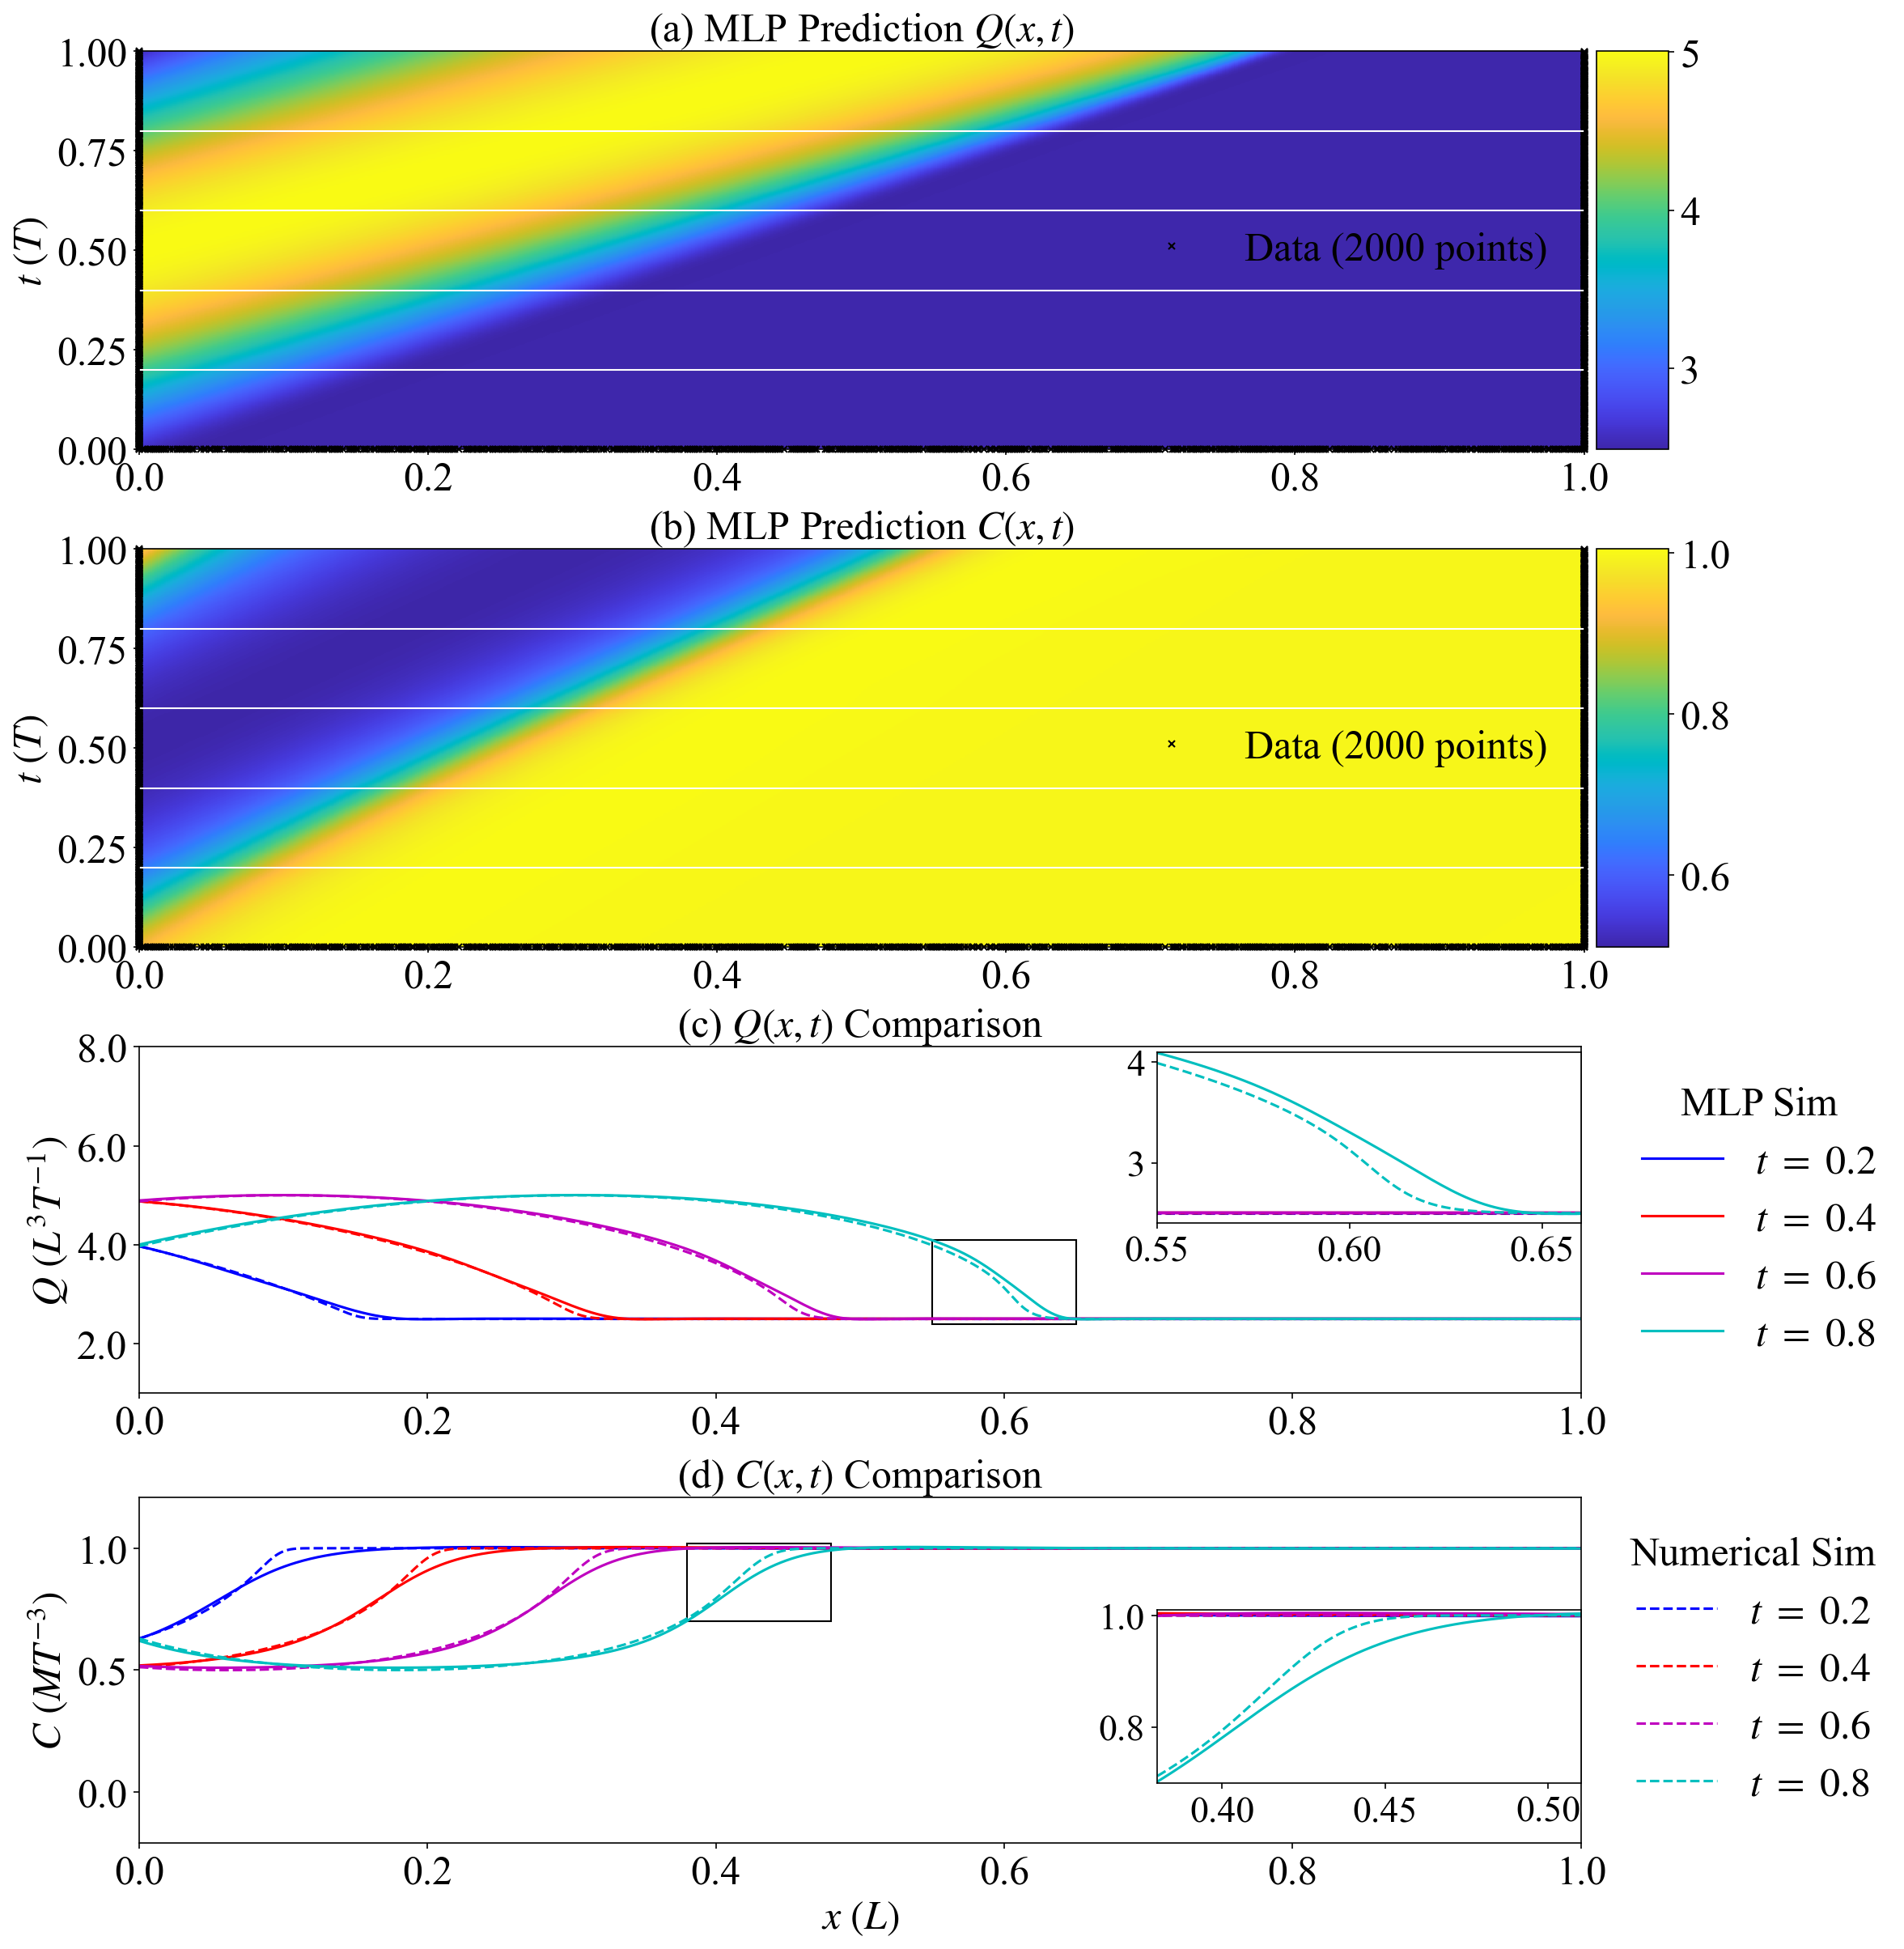

In [21]:


# Create professional layout canvas - adjust size to maintain same ratio as previous figuresfig = plt.figure(figsize=(18, 16.4), dpi=150)
ax = fig.add_subplot(111)
ax.axis('off')

# Adjust subplot position and sizegs0 = gridspec.GridSpec(1, 1)
gs0.update(top=1-0.05, bottom=1-1/4, left=0.15, right=0.85, wspace=0)
ax0 = plt.subplot(gs0[0, 0])
h = ax0.imshow(mlp_Q_pred, interpolation='nearest', cmap=colormap_parula,
               extent=[x.min(), x.max(), t.min(), t.max()],
               origin='lower', aspect='auto')
divider = make_axes_locatable(ax0)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(h, cax=cax)
cbar.ax.tick_params(labelsize=tick_font)
ax0.plot(X_u_train[:, 0], X_u_train[:, 1], 'kx', label='Data (%d points)' % (Q_u_train.shape[0]),
        markersize=4, clip_on=False)

tpos = np.array([200, 400, 600, 800])
colors = ['b', 'r', 'm', 'c', 'k']

line = np.linspace(x.min(), x.max(), 2)[:, None]
for i in tpos:
    ax0.plot(line, t[i] * np.ones((2, 1)), 'w-', linewidth=1)
ax0.set_ylabel('$t\ (T)$', fontsize=axis_label_font)
ax0.legend(frameon=False, loc='best', fontsize=legend_font)
ax0.set_title('(a) MLP Prediction $Q(x,t)$', fontsize=title_font)
ax0.tick_params(axis='both', labelsize=tick_font)

gs1 = gridspec.GridSpec(1, 1)
gs1.update(top=1 - 1/4 - 0.05, bottom=1 - 1 / 2, left=0.15, right=0.85, wspace=0)
ax1 = plt.subplot(gs1[0, 0])
h = ax1.imshow(mlp_C_pred, interpolation='nearest', cmap=colormap_parula,
               extent=[x.min(), x.max(), t.min(), t.max()],
               origin='lower', aspect='auto')
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(h, cax=cax)
cbar.ax.tick_params(labelsize=tick_font)
ax1.plot(X_u_train[:, 0], X_u_train[:, 1], 'kx', label='Data (%d points)' % (C_u_train.shape[0]),
        markersize=4, clip_on=False)

for i in tpos:
    ax1.plot(line, t[i] * np.ones((2, 1)), 'w-', linewidth=1)
ax1.set_ylabel('$t\ (T)$', fontsize=axis_label_font)
ax1.legend(frameon=False, loc='best', fontsize=legend_font)
ax1.set_title('(b) MLP Prediction $C(x,t)$', fontsize=title_font)
ax1.tick_params(axis='both', labelsize=tick_font)

gs2 = gridspec.GridSpec(2, 1)
gs2.update(top=1-1/2-0.05, bottom=0.05, left=0.15, right=0.81, hspace=0.3)

ax2 = plt.subplot(gs2[0, 0])
for i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax2.plot(x, mlp_Q_pred[i, :], color, label='$t\ =\ %.1f$' % ts)
    ax2.plot(x, Q[i, :], color + '--')
ax2.set_ylabel('$Q\ (L^3T^{-1})$', fontsize=axis_label_font)
ax2.set_xlim([x.min(), x.max()])
ax2.set_ylim([1, 8])
ax2.set_yticks([2, 4, 6, 8])
ax2.set_yticklabels(['2.0', '4.0', '6.0', '8.0'])
# Modify ax2 legend (MLP Sim)ax2.legend(title="MLP Sim",
           loc="right",
           bbox_to_anchor=(1.23,0.50),
           ncol=1, 
           frameon=False,
           fontsize=legend_font,                 # Keep original label font size           title_fontsize=legend_title_font)     # Separately increase title font sizeax2.set_title('(c) $Q(x,t)$ Comparison', fontsize=title_font)
ax2.tick_params(axis='both', labelsize=tick_font)

# Create inset subplot on ax2# ============= ax2 inset plot =============ax2_inset = inset_axes(
    ax2,
    width="30%",        # Subplot width    height="50%",       # Subplot height    loc=2,              # Location code (6 corresponds to "center left")    bbox_to_anchor=(0.7, 0.02, 0.98, 0.99),  # (x, y, width, height)
    bbox_transform=ax2.transAxes  
)

# Plot same curves in the inset subplotfor i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax2_inset.plot(x, mlp_Q_pred[i, :], color)
    ax2_inset.plot(x, Q[i, :], color + '--')

# Set coordinate range for the zoomed regionax2_inset.set_xlim(0.55, 0.66)
ax2_inset.set_ylim(2.4, 4.1)
ax2_inset.tick_params(labelsize=tick_font-2)    # Reduce tick font size for inset plot
# Remove mark_inset call, use rectangle frame to indicate zoom regionrect = Rectangle((0.55, 2.4), 0.1, 1.7, linewidth=1, edgecolor='black', facecolor='none', linestyle='-')
ax2.add_patch(rect)

ax3 = plt.subplot(gs2[1, 0])
for i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax3.plot(x, mlp_C_pred[i, :], color)
    ax3.plot(x, c[i, :], color + '--',label='$t\ =\ %.1f$' % ts)
ax3.set_xlabel('$x\ (L)$', fontsize=axis_label_font)
ax3.set_ylabel('$C\ (MT^{-3})$', fontsize=axis_label_font)
ax3.set_xlim([x.min(), x.max()])
ax3.set_ylim([-0.21, 1.21])
ax3.set_yticks([0, 0.5, 1])
# Modify ax3 legend (Numerical Sim)ax3.legend(title="Numerical Sim",
           loc="right",
           bbox_to_anchor=(1.23,0.50),
           ncol=1, 
           frameon=False,
           fontsize=legend_font,                 # Keep original label font size           title_fontsize=legend_title_font)     # Separately increase title font sizeax3.set_title('(d) $C(x,t)$ Comparison', fontsize=title_font)
ax3.tick_params(axis='both', labelsize=tick_font)

# ============= ax3 inset plot =============ax3_inset = inset_axes(
    ax3,
    width="30%",        # Subplot width    height="50%",       # Subplot height    loc=3,              # Location code (3 corresponds to "lower left")    bbox_to_anchor=(0.7, 0.15, 0.98, 1),  # (x, y, width, height)
    bbox_transform=ax3.transAxes  
)

for i, ts, color in zip(tpos, tpos * 0.001, colors):
    ax3_inset.plot(x, mlp_C_pred[i, :], color)
    ax3_inset.plot(x, c[i, :], color + '--')

ax3_inset.set_xlim(0.38, 0.51)
ax3_inset.set_ylim(0.7, 1.01)
ax3_inset.tick_params(labelsize=tick_font-2)    # Reduce tick font size for inset plot
# Remove mark_inset call, use rectangle frame to indicate zoom regionrect = Rectangle((0.38, 0.7), 0.10, 0.32, linewidth=1, edgecolor='black', facecolor='none', linestyle='-')
ax3.add_patch(rect)

# Save high-quality figureplt.savefig('111 MLP_Prediction_Results.png', 
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')
plt.savefig('111 MLP_Prediction_Results.pdf', 
           bbox_inches='tight', 
           dpi=600, 
           facecolor='white')

plt.show()

In [16]:
# Create performance comparison reportreport = f"""
Case4 Performance Report (Variable Concentration Source)
-------------------------------------------------------
Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
Device: {'GPU' if torch.cuda.is_available() else 'CPU'}

Model Parameters:
  MLP: {count_parameters(mlp_model):,} parameters
  KAN: {count_parameters(kan_model):,} parameters

MIN Relative L2 Errors:
  MLP: {np.min(mlp_L2_errors_Q):.4e}
  KAN: {np.min(kan_L2_errors_Q):.4e}
  MLP: {np.min(mlp_L2_errors_C):.4e}
  KAN: {np.min(kan_L2_errors_C):.4e}
MIN TOTAL  LOSS:
  mlp: {np.min(mlp_losses):.4e}
  kan: {np.min(kan_losses):.4e}
  

Training Details:
  Training points: {N_u}
  Collocation points: {N_f}
  Adam iterations: 10001
"""

# with open(f"{output_dir}/case4_performance_report.txt", "w") as f:
#     f.write(report)

print(report)


Case4 Performance Report (Variable Concentration Source)
-------------------------------------------------------
Date: 2026-06-24 02:56:49
Device: GPU

Model Parameters:
  MLP: 23,203 parameters
  KAN: 8,641 parameters

MIN Relative L2 Errors:
  MLP: 9.3094e-03
  KAN: 2.2473e-03
  MLP: 1.0334e-02
  KAN: 5.8806e-03
MIN TOTAL  LOSS:
  mlp: 2.4933e-04
  kan: 9.7724e-05
  

Training Details:
  Training points: 2000
  Collocation points: 8000
  Adam iterations: 10001

